# R-MOVE · ¿Las incidencias de Rodalies hacen que la gente deje de ir a Barcelona?

**Respuesta corta: sí, pero solo donde el tren no tiene alternativa.**

- En los días de caos, los municipios que **dependen de Rodalies** (a más de 20 km y sin metro ni FGC)
  hacen **entre un 7 % y un 10 % menos de viajes** a Barcelona; de media, en los 4 días, **−6,2 %** (sección 2).
- Los municipios con metro/FGC **no cambian** y los cercanos solo caen un poco (≈ −2 %): tienen otras formas de llegar (sección 3).
- **Cuanto más lejos, más impacto:** ≈ 0 % a menos de 15 km, ≈ −5,4 % entre 15 y 30 km y ≈ −7,3 % a más de 30 km (sección 3).
- **Cada línea reacciona distinto:** en una avería cae la línea cortada (Maresme, R1: −14 %); en las huelgas, el efecto
  depende del día y el Garraf (R2 Sud) es el corredor más afectado el 01/04/2025 (sección 4).
- **No todas las incidencias reducen los viajes:** una avería corta y por la tarde, aunque afecte a muchos
  viajeros, no cambia la movilidad (sección 4.5).
- **Una avería que deja una línea sin servicio normal durante horas también reduce los viajes, pero solo de esa línea:**
  Gavà (02/05/2023), R2 Sud −12 %; robo de cobre (22/11/2024), R4 Nord −10 % (sección 4.6).
- **El efecto dura un día** y no es casualidad: con 200 grupos de días normales al azar nunca sale una caída así (sección 5).

## Cómo leer este notebook

**La idea.** No basta con mirar si un día de incidencia hubo menos viajes: puede que ese día lloviera
o que fuera un día flojo para todo el mundo. Por eso se comparan dos grupos **el mismo día**:

- 🔴 **Dependientes:** municipios que necesitan Rodalies para llegar a Barcelona.
- ⚪ **Control:** municipios sin Rodalies. La incidencia no les afecta, así que indican
  «cómo habría sido el día sin incidencia».

Si los dos grupos caen igual, no es culpa del tren. Si los dependientes caen **más** que el control,
esa diferencia es el impacto de la incidencia.

**Cómo se mide (clustering).** Cada año, los días limpios se agrupan en 4 tipos según el volumen de los
municipios sin Rodalies y la época del año. Cada día de caos se compara con los días normales **de su mismo
tipo**, descontando lo que cambia el control ese día. Todas las cifras de los resultados salen de este método;
la regresión se usa como comprobación (anexo B).

| Si lees… | Significa… |
|---|---|
| **−7 %** | De cada 100 viajes que se harían en un día normal, 7 no se hacen |
| **Efecto claro** | La caída es mayor que la variación normal entre días (p < 0,05) |
| **No se distingue del ruido** | Puede haber efecto, pero es demasiado pequeño para asegurarlo |
| **Margen de error** (barra/línea) | Rango donde está el efecto real con un 95 % de seguridad. Si cruza el 0, no es concluyente |
| **Día limpio** | Laborable sin lluvia, festivos, verano, eventos ni incidencias: la referencia de «día normal» |

**Estructura**

| Parte | Contenido |
|---|---|
| **A. Preparación** | Datos, calendario, meteo y grupos de municipios. *Si solo quieres los resultados, sáltala.* |
| **1–5. Resultados** | Un día visto directamente → viajes perdidos → quién lo nota → cada línea → ¿es real? |
| **6. Conclusiones** | |
| **B. Anexo técnico** | Métodos en detalle, fórmulas, comparación con la regresión y exportaciones |

---
# A. Preparación de los datos

*Esta parte prepara todo lo necesario para los resultados. No hace falta leerla para entenderlos.*

In [1]:
%pip install holidays pyarrow openpyxl pyfixest -q
import re, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, holidays
import pyarrow.parquet as pq
import pyfixest as pf
from dateutil.easter import easter
from sklearn.cluster import KMeans
pd.set_option("display.max_rows", 100)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


### A.1 Configuración

In [2]:
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
OUT = PROC / "rmove"; OUT.mkdir(parents=True, exist_ok=True)

F_M2      = PROC / "telefonica" / "M2.parquet"
F_EST_MUN = OUT / "estaciones_rodalies_municipio.csv"
F_INC     = next((RAW / "rodalies").glob("Incidencias graves Rodalies*.xlsx"), None)
F_INC_OFICIAL = RAW / "rodalies" / "incidencias_rodalies_2023_2025.csv"
UMBRAL_REG    = 5000                  # regionales: solo se excluyen incidencias con ≥ 5.000 viajeros afectados

INICIO, FIN = "2023-01-01", "2025-08-31"
BCN_CODE    = "08019"
SEGMENTOS   = ["Regional", "Residente"]
LINEAS      = ["R1", "R2N", "R2S", "R3", "R4", "R7"]
MUN_CON_ALTERNATIVA = ["Sabadell", "Terrassa", "Rubí", "Sant Cugat del Vallès", "Martorell", "Manresa",
                       "Hospitalet de Llobregat, L'", "Badalona", "Cornellà de Llobregat", "Prat de Llobregat, El",
                       "Sant Adrià de Besòs", "Sant Joan Despí", "Sant Feliu de Llobregat"]
DIST_MIN_KM = 20                      # municipio dependiente: a ≥ 20 km de Barcelona y sin metro/FGC
MIN_VIAJES  = 200                     # municipios con al menos 200 viajes/día a Barcelona
VERANO      = ("06-21", "09-10")
LLUVIA_DIA, LLUVIA_MANANA, RACHA = 2.0, 0.5, 60
K_VOL       = 4                       # tipos de día del clustering (volumen del control + época del año), A–D por época

DIAS_CAOS = {"2024-05-13": "Avería: robo de cobre en Montcada (día 1)",
             "2025-03-17": "Huelga (caos generalizado)",
             "2025-03-19": "Huelga (paros parciales)",
             "2025-03-26": "Huelga 24 h",
             "2025-04-01": "Huelga 24 h"}
# Averías de una sola línea (sección 4.6). No entran en las medias de los días de caos: se miden solo en los
# municipios dependientes de la línea afectada («R4N» = R4 al norte de Barcelona). Fuente: registro oficial + prensa.
AVERIAS_LINEA = {
    "2023-05-02": ("R2S", "Avería: incendio del enclavamiento de Gavà (día 1), R2 Sud con servicio reducido"),
    "2024-11-22": ("R4N", "Avería: robo de cobre en la R4 entre Sabadell y Terrassa"),
    # "2025-05-08": ("R2S", "Avería: rotura de una aguja en Sitges (R2 Sud)"),  # descartada: ver sección 4.6
}
# Caso de contraste (sección 4.5): la avería con más viajeros afectados del registro oficial analizable
CASO_CONTRASTE = ("2025-06-05", "Avería: tren detenido entre Pl. Catalunya y Bif. Vilanova (14:25–16:14)")
for f in [F_M2, F_EST_MUN, F_INC, F_INC_OFICIAL]:
    print(("✅" if f is not None and f.exists() else "❌ NO EXISTE"), f)

✅ C:\Users\marti\R-MOVE\data\processed\telefonica\M2.parquet
✅ C:\Users\marti\R-MOVE\data\processed\rmove\estaciones_rodalies_municipio.csv
✅ C:\Users\marti\R-MOVE\data\raw\rodalies\Incidencias graves Rodalies 2023–2025.xlsx
✅ C:\Users\marti\R-MOVE\data\raw\rodalies\incidencias_rodalies_2023_2025.csv


### A.2 Datos

- **Movilidad (M2):** viajes diarios desde cada municipio de la provincia hacia Barcelona.
  Se usan los segmentos *Regional* y *Residente* (movilidad cotidiana); se excluyen *Nacional*
  e *Internacional* (turismo).
- **Estaciones:** cada estación de Rodalies asignada a su municipio (código INE) a partir del GTFS de Renfe.
- **Incidencias:** registro oficial de la Generalitat (define los días con incidencia que se excluyen de la
  referencia) y ranking de prensa de las 10 incidencias más graves (para elegir los días de caos).

In [3]:
cols = ["day", "origen", "municipio_origen", "municipio_origen_name", "municipio_destino", "viajes"]
if F_M2.suffix == ".parquet":
    mov = pq.read_table(F_M2, columns=cols, filters=[("municipio_destino", "==", BCN_CODE)]).to_pandas()
    if mov.empty:
        mov = pq.read_table(F_M2, columns=cols, filters=[("municipio_destino", "==", int(BCN_CODE))]).to_pandas()
else:
    mov = pd.read_csv(F_M2, usecols=cols, dtype={"municipio_origen": str, "municipio_destino": str})
mov["municipio_origen"] = mov.municipio_origen.astype(str).str.zfill(5)
mov["municipio_destino"] = mov.municipio_destino.astype(str).str.zfill(5)
mov = mov[(mov.municipio_destino == BCN_CODE) & (mov.municipio_origen != BCN_CODE) & mov.origen.isin(SEGMENTOS)]
mov["fecha"] = pd.to_datetime(mov.day)
mov = mov[(mov.fecha >= INICIO) & (mov.fecha <= FIN)]
nombres_mun = mov.drop_duplicates("municipio_origen").set_index("municipio_origen").municipio_origen_name
print(mov.shape, "|", mov.fecha.min().date(), "→", mov.fecha.max().date(), "| municipios de origen:", mov.municipio_origen.nunique())
mov["viajes"] = mov.viajes.astype(float)

(516238, 7) | 2023-01-01 → 2025-08-31 | municipios de origen: 308


In [4]:
est = pd.read_csv(F_EST_MUN, dtype={"stop_id": str, "municipio_code": str}).dropna(subset=["municipio_code"])
lineas = (est.assign(linea=est.lineas.str.split(",")).explode("linea")
             .query("linea in @LINEAS and municipio_code != @BCN_CODE")
             .drop_duplicates(["linea", "municipio_code"])[["linea", "municipio_code", "municipio"]])
display(lineas.groupby("linea").municipio.nunique().rename("municipios"))

linea
R1     19
R2N    13
R2S     8
R3     16
R4     25
R7      2
Name: municipios, dtype: int64

In [5]:
dias_inc = pd.read_excel(F_INC, sheet_name="Días afectados")
def lineas_de_texto(txt):
    t = str(txt)
    if re.search(r"general|total|toda la red|todas|casi toda", t, re.I):
        return list(LINEAS)
    out = set()
    for m in re.finditer(r"R(\d+)\s*(Nord|Sud|N\b|S\b)?", t, re.I):
        cod = f"R{m.group(1)}{(m.group(2) or '').upper()[:1]}"
        out |= {"R2N", "R2S"} if cod == "R2" else {cod}
    if re.search(r"regionales sur", t, re.I): out.add("R2S")
    return sorted(out & set(LINEAS))
dias_inc["lineas"] = dias_inc["Afectación ese día"].map(lineas_de_texto)
incid = (dias_inc.explode("lineas").dropna(subset=["lineas"])
         .rename(columns={"Fecha": "fecha", "lineas": "linea", "# ranking": "id_incidencia"})[["fecha", "linea", "id_incidencia"]])
incid["fecha"] = pd.to_datetime(incid.fecha)
print("Días con incidencia grave:", incid.fecha.nunique())

Días con incidencia grave: 64


**Incidencias graves.** Se parte de un ranking de las 10 incidencias más graves de Rodalies entre
2023 y agosto de 2025, elaborado a partir de noticias de prensa.
La gravedad combina, por orden de peso, el alcance (toda la red, varias líneas troncales o un tramo),
la duración, el tipo de interrupción (corte total, vía única o frecuencias reducidas) y el número de
viajeros afectados. Los días de caos analizados son el primer día del robo de cobre de Montcada
(13/05/2024) y tres jornadas de huelga de 2025 con alteración real del servicio.

**Días con incidencia.** Para definir los días limpios se usa una única regla basada en datos oficiales:
se excluyen todos los días con una incidencia de Rodalies BCN en el registro de la Generalitat
(solicitud TER_2026_EXP_SIP001SOL2_00019332; recoge las de más de 10.000 viajeros afectados).
Como el registro solo marca el primer día de cada incidencia, se excluye además todo el periodo de los
cortes largos documentados (Gavà, 02–19/05/2023; Montcada, 13/05–14/06/2024; apagón, 28–30/04/2025).
El ranking de prensa solo se usa para elegir los días de caos que se analizan.
Comprobación: sin excluir ninguna incidencia, el efecto medio pasa de −6,2 % a −5,0 % y sigue siendo claro.

In [6]:
inc_of = pd.read_csv(F_INC_OFICIAL, parse_dates=["fecha"])
inc_of = inc_of[inc_of.servicio == "rodalies_bcn"]          # solo Rodalies BCN (≥ 10.000 viajeros afectados)
dias_inc_oficial = pd.DatetimeIndex(inc_of.fecha.unique())
print("Días con incidencia de Rodalies BCN en el registro oficial:", len(dias_inc_oficial))

Días con incidencia de Rodalies BCN en el registro oficial: 84


### A.3 Días de referencia («días limpios»)

Para saber qué es un día «normal», se descartan los días con un comportamiento distinto:
fines de semana, festivos (Cataluña y Barcelona), puentes, Navidad, Semana Santa, verano
(21/06–10/09), eventos (MWC, Sant Jordi, apagón), huelgas, días de mal tiempo (lluvia ≥ 2 mm/día,
≥ 0,5 mm entre las 6 y las 10 h o rachas ≥ 60 km/h, ponderadas por los viajes de cada municipio)
y días con incidencias de Rodalies BCN según el registro oficial de la Generalitat, más todo el periodo de los
cortes largos (A.2). Los días de caos y las averías de una línea (sección 4.6) tampoco cuentan como días limpios.

**Control de calidad:** en el análisis exploratorio se detectaron cinco días con errores en los
datos de origen (05/06/2023, 12/02/2024, 07/03/2024, 19/05/2025 y 21/05/2025): caídas del 25–70 %
en todos los municipios, incluidos L'Hospitalet (con metro) y los visitantes internacionales. Se
excluyen como «anomalía de datos».

**Calendario.** Se marca cada día del periodo según si es fin de semana, festivo (Cataluña y
Barcelona), puente, Navidad, Semana Santa o verano, y se añaden los días especiales: MWC,
Sant Jordi, apagón, huelgas y los cinco días con anomalías en los datos.

In [7]:
cal = pd.DataFrame(index=pd.date_range(INICIO, FIN, freq="D"))
cal["dow"] = cal.index.day_of_week
cal["finde"] = cal.dow >= 5
md_ = cal.index.strftime("%m-%d")
anys = range(int(INICIO[:4]), int(FIN[:4]) + 1)
fest_ct = holidays.Spain(subdiv="CT", years=anys)
locales_bcn = pd.to_datetime(["2023-05-29", "2023-09-25", "2024-05-20", "2024-09-24", "2025-06-09"])
cal["festivo"] = cal.index.isin(pd.to_datetime(list(fest_ct.keys()))) | cal.index.isin(locales_bcn)
no_lab = cal.finde | cal.festivo
cal["puente"] = ~no_lab & no_lab.shift(1, fill_value=False) & no_lab.shift(-1, fill_value=False)
cal["navidad"] = (md_ >= "12-22") | (md_ <= "01-07")
ss = []
for y in anys:
    e = pd.Timestamp(easter(y)); ss += list(pd.date_range(e - pd.Timedelta(days=8), e + pd.Timedelta(days=1)))
cal["semana_santa"] = cal.index.isin(ss)
cal["verano"] = (md_ >= VERANO[0]) & (md_ <= VERANO[1])

eventos = {
    "MWC": list(pd.date_range("2023-02-27", "2023-03-02")) + list(pd.date_range("2024-02-26", "2024-02-29"))
         + list(pd.date_range("2025-03-03", "2025-03-06")),
    "Sant Jordi": list(pd.to_datetime(["2024-04-23", "2025-04-23"])),
    "Apagón": [pd.Timestamp("2025-04-28")],
    "Anomalía de datos": list(pd.to_datetime(["2023-06-05", "2024-02-12", "2024-03-07", "2025-05-19", "2025-05-21"])),
    "Huelgas": list(pd.to_datetime(["2023-11-23", "2023-11-24", "2024-02-09", "2024-02-16",
                                    "2025-03-17", "2025-03-19", "2025-03-26", "2025-04-01"])),
}
cal["evento"], cal["evento_nombre"] = False, ""
for nombre, dias in eventos.items():
    m = cal.index.isin(dias); cal.loc[m, "evento"] = True; cal.loc[m, "evento_nombre"] = nombre

**Meteorología.** Se descarga la lluvia y el viento diarios de Open-Meteo para cada municipio
con estación (se guarda en caché). Se calcula la lluvia media ponderada por los viajes de cada
municipio y se marca como «mal tiempo» el día con lluvia ≥ 2 mm, ≥ 0,5 mm entre las 6 y las 10 h,
lluvia en Barcelona ≥ 2 mm o rachas ≥ 60 km/h.

In [8]:
def meteo(lat, lon):
    p = dict(latitude=lat, longitude=lon, start_date=INICIO, end_date=FIN,
             daily="precipitation_sum,wind_gusts_10m_max", hourly="precipitation", timezone="Europe/Madrid")
    j = requests.get("https://archive-api.open-meteo.com/v1/archive", params=p, timeout=60).json()
    if "daily" not in j: raise RuntimeError(j)
    d = pd.DataFrame(j["daily"]); d["time"] = pd.to_datetime(d.time); d = d.set_index("time")
    h = pd.DataFrame(j["hourly"]); h["time"] = pd.to_datetime(h.time); h = h.set_index("time")
    d["lluvia_manana"] = h.between_time("06:00", "10:00").precipitation.resample("D").sum()
    return d

coords = est.groupby("municipio_code")[["stop_lat", "stop_lon"]].mean()
coords = coords[coords.index.isin(set(lineas.municipio_code) | {BCN_CODE})]
alt_codes = set(lineas.loc[lineas.municipio.isin(MUN_CON_ALTERNATIVA), "municipio_code"])
pesos = (mov[mov.municipio_origen.isin(set(lineas.municipio_code) - alt_codes)]
           .groupby("municipio_origen").viajes.sum().astype(float) / mov.fecha.nunique())

cache = OUT / f"meteo_{INICIO}_{FIN}.parquet"
if cache.exists():
    meteo_long = pd.read_parquet(cache)
else:
    trozos = []
    for code_, (lat, lon) in coords.iterrows():
        d = None
        for intento in range(5):
            try: d = meteo(lat, lon); break
            except Exception as e: print(code_, "reintento", intento, e); time.sleep(65)
        if d is not None:
            trozos.append(d[["precipitation_sum", "lluvia_manana", "wind_gusts_10m_max"]].assign(municipio_code=code_))
        time.sleep(6)
    meteo_long = pd.concat(trozos).rename_axis("fecha").reset_index(); meteo_long.to_parquet(cache)

def ponderada(col):
    w = meteo_long.pivot(index="fecha", columns="municipio_code", values=col).astype(float)
    w = w[[c for c in w.columns if c in pesos.index]]
    p = pesos.reindex(w.columns).astype(float).to_numpy()
    num = np.nansum(w.to_numpy() * p, axis=1)
    den = (w.notna().to_numpy() * p).sum(axis=1)
    return pd.Series(np.where(den > 0, num / den, np.nan), index=w.index)

cal["lluvia_pond"] = ponderada("precipitation_sum")
cal["lluvia_manana_pond"] = ponderada("lluvia_manana")
cal["racha_pond"] = ponderada("wind_gusts_10m_max")
cal["lluvia_bcn"] = meteo_long[meteo_long.municipio_code == BCN_CODE].set_index("fecha").precipitation_sum
cal["mal_tiempo"] = ((cal.lluvia_pond >= LLUVIA_DIA) | (cal.lluvia_manana_pond >= LLUVIA_MANANA)
                     | (cal.lluvia_bcn >= LLUVIA_DIA) | (cal.racha_pond >= RACHA)).fillna(False)

**Días limpios y días de caos.** Un día es «limpio» (referencia de un día normal) si no cumple
ninguno de los motivos de exclusión, no tiene incidencia de Rodalies BCN en el registro oficial, no está
dentro de un corte largo y no es una de las averías de una línea analizadas. La tabla muestra cuántos días
excluye cada motivo. Por último, se seleccionan los días de caos que se pueden analizar
(laborables, fuera de verano y sin lluvia).

In [9]:
motivos = ["finde", "festivo", "puente", "navidad", "semana_santa", "verano", "evento", "mal_tiempo"]
cal["base_ok"] = ~cal[motivos].any(axis=1)
# Cortes largos: el registro oficial solo marca el primer día; se excluye todo el periodo afectado
CORTES_LARGOS = (pd.date_range("2023-05-02", "2023-05-19")      # incendio del enclavamiento de Gavà
                 .union(pd.date_range("2024-05-13", "2024-06-14"))  # robo de cobre en Montcada
                 .union(pd.date_range("2025-04-28", "2025-04-30"))) # apagón y recuperación del servicio
averias_linea = pd.DatetimeIndex(pd.to_datetime(list(AVERIAS_LINEA)))
cal["limpio"] = (cal.base_ok & ~cal.index.isin(dias_inc_oficial) & ~cal.index.isin(CORTES_LARGOS)
                 & ~cal.index.isin(averias_linea))           # un día analizado como avería nunca es día normal
print("Días laborables descartados por el registro oficial:", (cal.base_ok & cal.index.isin(dias_inc_oficial)).sum(),
      "· por los cortes largos:", (cal.base_ok & cal.index.isin(CORTES_LARGOS) & ~cal.index.isin(dias_inc_oficial)).sum())
display(pd.DataFrame({"días excluidos": cal[motivos].sum(),
                      "excluidos solo por este motivo": cal[motivos][cal[motivos].sum(axis=1) == 1].sum()}))
print("Días limpios por año:", cal[cal.limpio].groupby(cal[cal.limpio].index.year).size().to_dict())

caos_real = [pd.Timestamp(d) for d in DIAS_CAOS
             if INICIO <= d <= FIN and not (cal.at[pd.Timestamp(d), "finde"] or cal.at[pd.Timestamp(d), "festivo"]
                                             or cal.at[pd.Timestamp(d), "verano"] or cal.at[pd.Timestamp(d), "mal_tiempo"])]
display(pd.DataFrame({"descripción": [DIAS_CAOS[d.strftime("%Y-%m-%d")] for d in caos_real],
                      "lluvia_mm": [round(cal.at[d, "lluvia_pond"], 1) for d in caos_real]}, index=[d.date() for d in caos_real]))
print("Días de caos descartados:", [d for d in DIAS_CAOS if pd.Timestamp(d) not in caos_real])

Días laborables descartados por el registro oficial: 27 · por los cortes largos: 22


,días excluidos,excluidos solo por este motivo
finde,279,135
festivo,38,12
puente,8,2
navidad,41,18
semana_santa,30,6
verano,236,127
evento,28,22
mal_tiempo,233,112


Días limpios por año: {2023: 119, 2024: 97, 2025: 57}


,descripción,lluvia_mm
2024-05-13,Avería: robo de cobre en Montcada (día 1),0.0
2025-03-17,Huelga (caos generalizado),0.5
2025-03-26,Huelga 24 h,0.4
2025-04-01,Huelga 24 h,0.1


Días de caos descartados: ['2025-03-19']


**Resultado.** Quedan 273 días laborables limpios (119 en 2023, 97 en 2024 y 57 en 2025, año parcial).
El registro oficial descarta 27 días laborables y los cortes largos, 22 más. Se analizan **4 días de caos**: el 13/05/2024 (robo de cobre en Montcada) y las huelgas del
17/03, 26/03 y 01/04/2025. El 19/03/2025 se descarta por lluvia intensa (26 mm). Las huelgas de
noviembre de 2023 no se incluyen porque se desconvocaron y el servicio fue casi normal.
Además, en la sección 4.5 se estudia aparte un **caso de contraste** (la avería del 05/06/2025) y en la 4.6,
dos **averías de una sola línea** (02/05/2023 y 22/11/2024).

### A.4 Grupos de municipios

Cada municipio con al menos 200 viajes diarios a Barcelona se clasifica en:

| Grupo | Definición | Papel |
|---|---|---|
| **Dependiente** | Estación de Rodalies, sin metro ni FGC y a ≥ 20 km de Barcelona | Tratado: depende del tren |
| **Cercano sin metro/FGC** | Estación de Rodalies, sin metro ni FGC, a < 20 km | Tiene bus metropolitano |
| **Con metro/FGC** | Estación de Rodalies y metro o FGC | Tiene alternativa ferroviaria |
| **Sin Rodalies** | Sin estación de Rodalies | **Control**: ninguna incidencia de Rodalies le afecta |

In [10]:
PLAZA_CAT = (41.3874, 2.1686)
def km(lat, lon):
    la1, lo1, la2, lo2 = map(np.radians, [lat, lon, *PLAZA_CAT])
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))

lineas_mun = lineas.groupby("municipio_code").agg(lineas=("linea", lambda s: frozenset(s)), municipio=("municipio", "first"))
lineas_mun["linea_dep"] = lineas_mun.lineas.map(lambda s: "+".join(sorted(s)))
lineas_mun["con_alternativa"] = lineas_mun.municipio.isin(MUN_CON_ALTERNATIVA)
lineas_mun["dist_km"] = est.groupby("municipio_code")[["stop_lat", "stop_lon"]].mean().apply(
    lambda r: km(r.stop_lat, r.stop_lon), axis=1).reindex(lineas_mun.index).round(1)
lineas_mun["dependiente"] = ~lineas_mun.con_alternativa & (lineas_mun.dist_km >= DIST_MIN_KM)

# Panel municipio × día: días limpios + días de caos
todos = mov.groupby(["municipio_origen", "fecha"]).viajes.sum().rename("viajes").reset_index().rename(columns={"municipio_origen": "municipio_code"})
todos = todos[todos.fecha.isin(cal.index[cal.limpio]) | todos.fecha.isin(caos_real)
              | (todos.fecha == pd.Timestamp(CASO_CONTRASTE[0]))           # + caso de contraste (4.5)
              | todos.fecha.isin(averias_linea)]                           # + averías de una línea (4.6)
media = todos.groupby("municipio_code").viajes.mean()
todos = todos[todos.municipio_code.isin(media.index[media >= MIN_VIAJES]) & (todos.viajes > 0)]
todos["y"] = np.log(todos.viajes)
todos["mun_dow"] = todos.municipio_code + "_" + todos.fecha.dt.day_of_week.astype(str)

info = pd.DataFrame(index=todos.municipio_code.unique())
info["municipio"] = info.index.map(nombres_mun)
info["rodalies"] = info.index.isin(lineas_mun.index)
info["dependiente"] = info.index.map(lineas_mun.dependiente).fillna(False).astype(bool)
info["con_alt"] = info.index.map(lineas_mun.con_alternativa).fillna(False).astype(bool)
info["dist_km"] = info.index.map(lineas_mun.dist_km)
info["lineas"] = info.index.map(lineas_mun.linea_dep).fillna("—")
info["grupo"] = np.select([~info.rodalies, info.dependiente, info.con_alt],
                          ["Sin Rodalies (control)", "Dependiente", "Con metro/FGC"], "Cercano sin metro/FGC")
ctrl_codes = list(info.index[~info.rodalies])
display(info.groupby("grupo").agg(municipios=("municipio", "size"), ejemplos=("municipio", lambda s: ", ".join(sorted(s)[:5]))))
print("Dependientes:", ", ".join(info[info.dependiente].sort_values("dist_km").municipio))

,municipios,ejemplos
grupo,,
Cercano sin metro/FGC,16,"Barberà del Vallès, Castellbisbal, Cerdanyola ..."
Con metro/FGC,11,"Badalona, Cornellà de Llobregat, Hospitalet de..."
Dependiente,35,"Arenys de Mar, Balenyà, Cabrera de Mar, Caldes..."
Sin Rodalies (control),71,"Abrera, Alella, Ametlla del Vallès, L', Arenys..."


Dependientes: Castelldefels, Vilassar de Mar, Cabrera de Mar, Granollers, Viladecavalls, Gelida, Mataró, Franqueses del Vallès, Les, Sitges, Sant Sadurní d'Anoia, Vacarisses, Cardedeu, Sant Andreu de Llavaneres, Subirats, Llinars del Vallès, Garriga, La, Caldes d'Estrac, Castellbell i el Vilar, Arenys de Mar, Vilafranca del Penedès, Santa Maria de Palautordera, Sant Vicenç de Castellet, Canet de Mar, Vilanova i la Geltrú, Sant Celoni, Sant Pol de Mar, Cubelles, Centelles, Calella, Balenyà, Pineda de Mar, Malgrat de Mar, Tordera, Vic, Manlleu


**Resultado.** 35 municipios dependientes (de Castelldefels, a 21 km, a Manlleu, a 69 km), 16 cercanos
sin metro/FGC, 11 con metro/FGC y 71 municipios sin Rodalies como control.

### A.5 Herramientas de cálculo

Se definen las funciones que se usan en los resultados. El detalle de cada método está en el **anexo B**.

- **Tipo de día (clustering):** cada año, los días limpios se agrupan en 4 tipos (A–D) según los viajes
  de los municipios sin Rodalies y la época del año. Sirve para comparar cada día de caos con días normales parecidos.
- **Efecto (clustering):** cambio del grupo respecto a los días normales del mismo tipo, descontando el cambio
  de los municipios sin Rodalies ese mismo día. El margen de error y la p salen de tratar cada día limpio como
  un falso día de caos. **Es la cifra que se usa en todos los resultados.**
- **Efecto (regresión):** compara, el mismo día, el grupo analizado con los municipios sin Rodalies.
  Se usa como **comprobación** (anexo B).

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

V = todos.pivot_table(index="fecha", columns="municipio_code", values="viajes")
vol_ctrl = np.log(V[ctrl_codes].sum(axis=1, min_count=len(ctrl_codes) // 2))

def variables_dia(dias, vol=None):
    """Variables del clustering: log del volumen de los municipios sin Rodalies y época del año (día del año / 365)."""
    vol = vol_ctrl if vol is None else vol
    dias = pd.DatetimeIndex(dias)
    return pd.DataFrame({"vol": vol.reindex(dias).values, "epoca": dias.day_of_year / 365}, index=dias)

def ajustar_tipos(dias):
    """K-means (k = K_VOL) sobre las dos variables estandarizadas."""
    return make_pipeline(StandardScaler(), KMeans(K_VOL, n_init=10, random_state=0)).fit(variables_dia(dias))

modelos = {}
for y in sorted(cal.index.year.unique()):
    dias = cal.index[cal.limpio & (cal.index.year == y)].intersection(vol_ctrl.dropna().index)
    if len(dias) < 2 * K_VOL:
        continue
    pipe = ajustar_tipos(dias)
    centros = pipe[0].inverse_transform(pipe[-1].cluster_centers_)          # columnas: vol, época
    nombre = {c: "ABCD"[i] for i, c in enumerate(np.argsort(centros[:, 1]))} # A–D ordenados por época del año
    tipos = pd.Series([nombre[c] for c in pipe[-1].labels_], index=dias)
    modelos[y] = (pipe, nombre, tipos)
    resumen = pd.DataFrame({
        "días": tipos.value_counts().sort_index(),
        "primer – último día": tipos.groupby(tipos).apply(lambda s: f"{s.index.min():%d/%m} – {s.index.max():%d/%m}"),
        "viajes medios (sin Rodalies)": np.exp(vol_ctrl.loc[dias]).groupby(tipos).mean().round(0)})
    print(f"\n{y}"); display(resumen)

def tipo_de_dia(d, vol=None):
    pipe, nombre, _ = modelos[d.year]
    return nombre[pipe.predict(variables_dia([d], vol))[0]]

def dias_mismo_tipo(d):
    """Días limpios del mismo año y del mismo tipo que d (sus «días normales parecidos»)."""
    _, _, tipos = modelos[d.year]
    return tipos.index[tipos == tipo_de_dia(d)]

# Placebos: cada día limpio se trata como un falso día de caos, reentrenando el clustering sin él
REF_LOO = {}
for y, (_, _, tipos) in modelos.items():
    for d in tipos.index:
        resto = tipos.index.drop(d)
        p_ = ajustar_tipos(resto)
        REF_LOO[d] = resto[p_[-1].labels_ == p_.predict(variables_dia([d]))[0]]
print(f"\n{len(REF_LOO)} días limpios con placebo")


2023


,días,primer – último día,viajes medios (sin Rodalies)
A,14,09/01 – 13/03,184476.0
B,27,10/01 – 18/09,197240.0
C,34,09/02 – 20/06,211295.0
D,44,14/09 – 21/12,211999.0



2024


,días,primer – último día,viajes medios (sin Rodalies)
A,27,08/01 – 17/06,195364.0
B,34,24/01 – 19/06,209153.0
C,18,13/09 – 16/12,201574.0
D,18,17/09 – 20/12,214175.0



2025


,días,primer – último día,viajes medios (sin Rodalies)
A,12,08/01 – 17/02,197078.0
B,18,15/01 – 04/04,208779.0
C,16,27/03 – 19/06,216857.0
D,10,25/04 – 20/06,204201.0



272 días limpios con placebo


In [12]:
s_ctrl = V[ctrl_codes].sum(axis=1, min_count=1)
_pct = lambda x: (np.exp(x) - 1) * 100
_cache_plac = {}

def _ef_log(s, d, ref):
    """Efecto (en log) del día d frente a los días ref, corregido por el control."""
    return np.log(s.loc[d] / s.loc[ref].median()) - np.log(s_ctrl.loc[d] / s_ctrl.loc[ref].median())

def placebos_clustering(codes):
    """Efecto en cada día limpio tratado como falso día de caos (clustering reentrenado sin ese día)."""
    codes = tuple(sorted(c for c in codes if c in V.columns))
    if codes not in _cache_plac:
        s = V[list(codes)].sum(axis=1, min_count=1)
        p = np.array([_ef_log(s, d, ref) for d, ref in REF_LOO.items()])
        _cache_plac[codes] = p[np.isfinite(p)]
    return _cache_plac[codes]

def metodo_clustering(codes, dias, n_sim=20000, seed=0):
    """Efecto corregido por el control: (grupo / su mediana en los días del mismo tipo)
    ÷ (lo mismo para los municipios sin Rodalies) − 1.
    p e IC95 a partir de los placebos (días limpios, con el clustering reentrenado sin ese día).
    Devuelve: efecto %, p, IC inferior %, IC superior %."""
    s = V[[c for c in codes if c in V.columns]].sum(axis=1, min_count=1)
    efs = np.array([_ef_log(s, d, dias_mismo_tipo(d)) for d in dias])
    efs = efs[np.isfinite(efs)]
    if len(efs) == 0:
        return np.nan, np.nan, np.nan, np.nan
    plac = placebos_clustering(codes)
    obs = efs.mean()
    dist = plac if len(efs) == 1 else np.random.default_rng(seed).choice(plac, (n_sim, len(efs))).mean(axis=1)
    p = (1 + (dist <= obs).sum()) / (len(dist) + 1)
    lo, hi = obs - np.quantile(dist, .975), obs - np.quantile(dist, .025)
    return _pct(obs), p, _pct(lo), _pct(hi)

def metodo_regresion(codes, dias):
    """Diferencias en diferencias: grupo vs. municipios sin Rodalies, mismo día."""
    sub = todos[todos.fecha.isin(cal.index[cal.limpio]) | todos.fecha.isin(dias)]
    sub = sub[sub.municipio_code.isin(codes) | sub.municipio_code.isin(ctrl_codes)].copy()
    sub["trat"] = (sub.fecha.isin(dias) & sub.municipio_code.isin(codes)).astype(int)
    t = pf.feols("y ~ trat | mun_dow + fecha", data=sub, vcov={"CRV1": "municipio_code"}).tidy().iloc[0]
    return (np.exp(t.Estimate) - 1) * 100, (np.exp(t["2.5%"]) - 1) * 100, (np.exp(t["97.5%"]) - 1) * 100, t["Pr(>|t|)"]

def comparar(grupos, dias):
    """Tabla por grupo: efecto del clustering (cifra principal: cambio_%, IC95, p) y de la regresión (comprobación)."""
    filas = []
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in V.columns]
        if not codes: continue
        e1, p1, lo1, hi1 = metodo_clustering(codes, dias)
        e2, lo, hi, p2 = metodo_regresion(codes, dias)
        filas.append({"grupo": nombre, "municipios": len(codes),
                      "cambio_%": round(e1, 1), "IC95": f"[{lo1:.1f}, {hi1:.1f}]", "p": round(p1, 3),
                      "clustering_%": round(e1, 1), "clustering_p": round(p1, 3),
                      "regresión_%": round(e2, 1), "regresión_IC95": f"[{lo:.1f}, {hi:.1f}]", "regresión_p": round(p2, 3)})
    return pd.DataFrame(filas).set_index("grupo")

def grafico_barras(tabla, titulo):
    ax = tabla[["clustering_%", "regresión_%"]].iloc[::-1].plot.barh(figsize=(9, 0.6 * len(tabla) + 1.5), color=["C1", "C0"])
    ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("% cambio de viajes a Barcelona"); ax.set_ylabel("")
    ax.set_title(titulo); plt.tight_layout(); plt.show()

In [13]:
# ── Auxiliares para los gráficos de resultados ──────────────────────────────
from IPython.display import Markdown

ROJO, GRIS = "#C0392B", "0.55"
dep = info[info.dependiente]                                    # municipios dependientes

# Viajes diarios por municipio (TODOS los días, no solo los limpios) y totales por grupo
V_all = mov.pivot_table(index="fecha", columns="municipio_origen", values="viajes", aggfunc="sum")
DEP  = [c for c in dep.index if c in V_all.columns]
CTRL = [c for c in ctrl_codes if c in V_all.columns]
tot_dep  = V_all[DEP].sum(axis=1, min_count=len(DEP) // 2)
tot_ctrl = V_all[CTRL].sum(axis=1, min_count=len(CTRL) // 2)

NOMBRE_LINEA = {"R1": "Maresme", "R2N": "Vallès Oriental", "R2S": "Garraf", "R3": "Osona",
                "R4": "Penedès–Bages", "R7": "Cerdanyola", "R2N+R3": "Granollers"}
ETQ = {d: f"{d:%d/%m/%y}\n{'Avería' if 'Avería' in DIAS_CAOS[d.strftime('%Y-%m-%d')] else 'Huelga'}"
       for d in caos_real}
miles = lambda v: f"{v:,.0f}".replace(",", ".")

def viajes_normales(codes, d):
    """Viajes del grupo en un día normal: mediana de los días limpios del mismo tipo de día."""
    codes = [c for c in codes if c in V_all.columns]
    _, _, tipos = modelos[d.year]
    ref = tipos.index[tipos == tipo_de_dia(d)]
    return V_all.loc[V_all.index.intersection(ref), codes].sum(axis=1, min_count=1).median()

def ic(tabla):
    """Separa la columna 'IC95' ('[lo, hi]') del clustering en dos columnas numéricas."""
    t = tabla.copy()
    t[["lo", "hi"]] = t["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
    return t


def grafico_dia(dia, ventana=10, codes=None, etiqueta="Dependientes de Rodalies"):
    """Viajes de dependientes y control alrededor de un día de caos (100 = día normal).
    codes: municipios a dibujar en rojo (por defecto, todos los dependientes)."""
    d = pd.Timestamp(dia)
    s_dep = tot_dep if codes is None else V_all[[c for c in codes if c in V_all.columns]].sum(axis=1, min_count=1)
    lab = cal.index[~(cal.finde | cal.festivo)]                  # solo laborables
    i = lab.get_loc(d)
    fechas = lab[max(0, i - ventana): i + ventana + 1]
    ref = fechas[cal.loc[fechas, "limpio"].values]                # días limpios de la ventana
    if len(ref) < 5:
        ref = cal.index[cal.limpio & (cal.index.year == d.year)]
    idx_dep  = s_dep.reindex(fechas)  / s_dep.reindex(ref).median()  * 100
    idx_ctrl = tot_ctrl.reindex(fechas) / tot_ctrl.reindex(ref).median() * 100
    lo, hi = idx_dep.reindex(ref).quantile([.05, .95])
    x, j = np.arange(len(fechas)), list(fechas).index(d)
    limpio = cal.loc[fechas, "limpio"].values

    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax.axhspan(lo, hi, color="0.92", zorder=0, label="Variación normal de los dependientes")
    ax.axhline(100, color="black", lw=.6)
    ax.plot(x, idx_ctrl.values, "-", color=GRIS, lw=1.5, label="Sin Rodalies (control)")
    ax.plot(x, idx_dep.values, "-", color=ROJO, lw=2.2, label=etiqueta)
    for serie, c in [(idx_ctrl, GRIS), (idx_dep, ROJO)]:            # punto lleno = día limpio, vacío = otro
        ax.scatter(x, serie.values, s=28, zorder=3, color=np.where(limpio, c, "white"), edgecolor=c)
    for f in fechas:
        if f in caos_real and f != d:
            ax.axvline(list(fechas).index(f), color=ROJO, ls=":", lw=.8, alpha=.5)
    ax.axvline(j, color=ROJO, ls="--", lw=1)
    ax.annotate(f"Dependientes: {idx_dep.loc[d] - 100:+.0f} %\nControl: {idx_ctrl.loc[d] - 100:+.0f} %",
                (j, idx_dep.loc[d]), xytext=(12, 0), textcoords="offset points", va="center",
                color=ROJO, fontweight="bold", fontsize=9)
    ymin = min(idx_dep.min(), idx_ctrl.min(), lo); ymax = max(idx_dep.max(), idx_ctrl.max(), hi)
    ax.set_ylim(ymin - 2, ymax + (ymax - ymin) * .35)                 # espacio arriba para la leyenda
    dias_es = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
    ax.set_xticks(x); ax.set_xticklabels([f"{dias_es[f.day_of_week]} {f:%d/%m}" for f in fechas], rotation=90, fontsize=8)
    ax.set_ylabel("Viajes a Barcelona\n(100 = día normal)")
    ax.set_title(f"{d:%d/%m/%Y} · {DIAS_CAOS[d.strftime('%Y-%m-%d')]}", loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=8, ncol=3)
    plt.tight_layout(); plt.show()


def grafico_efectos(tabla, titulo):
    """Un punto por grupo con su margen de error. Rojo = efecto claro; gris = no se distingue del ruido."""
    t = ic(tabla).iloc[::-1]
    claro = ((t["p"] < 0.05) & (t["cambio_%"] < 0)).values
    col = np.where(claro, ROJO, "0.6")
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(10, 0.75 * len(t) + 1.4))
    ax.axvline(0, color="black", lw=.8)
    ax.hlines(y, t.lo, t.hi, color=col, lw=5, alpha=.35)
    ax.scatter(t["cambio_%"], y, color=col, s=90, zorder=3)
    for yi in y:
        txt = "efecto claro" if claro[yi] else "no se distingue del ruido"
        ax.text(t.hi.iloc[yi] + .5, yi, f"{t['cambio_%'].iloc[yi]:+.1f} %  · {txt}",
                va="center", fontsize=9, color=col[yi])
    ax.set_xlim(min(t.lo.min(), 0) - 2, max(t.hi.max(), 0) + 12)
    ax.set_yticks(y); ax.set_yticklabels(t.index)
    ax.set_xlabel("Cambio en los viajes a Barcelona respecto a lo esperado (%)")
    ax.set_title(titulo, loc="left", fontweight="bold")
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout(); plt.show()

In [14]:
coords_mun = est.groupby("municipio_code")[["stop_lat", "stop_lon"]].mean()

_plac_mun = {}

def placebos_municipio():
    """Efecto (log) de cada municipio en cada día limpio tratado como falso día de caos."""
    if "P" not in _plac_mun:
        lv, lc = np.log(V), np.log(s_ctrl)
        _plac_mun["P"] = pd.DataFrame({d: (lv.loc[d] - np.log(V.loc[ref].median()))
                                          - (lc.loc[d] - np.log(s_ctrl.loc[ref].median()))
                                       for d, ref in REF_LOO.items()}).T
    return _plac_mun["P"]

def efectos_municipio(DIA):
    """Efecto por municipio (clustering, corregido por el control) con su z y su p (bilateral, por placebos)."""
    DIA = pd.Timestamp(DIA)
    ref = dias_mismo_tipo(DIA)
    ef_log = (np.log(V.loc[DIA]) - np.log(V.loc[ref].median())) - (np.log(s_ctrl.loc[DIA]) - np.log(s_ctrl.loc[ref].median()))
    P = placebos_municipio().reindex(columns=ef_log.index)
    n = P.notna().sum()
    p_baja = (P.le(ef_log, axis=1).sum() + 1) / (n + 1)
    p_alta = (P.ge(ef_log, axis=1).sum() + 1) / (n + 1)
    r = info[info.rodalies].join(coords_mun).copy()
    r["efecto_%"] = _pct(ef_log).reindex(r.index).round(1)
    r["z"] = (ef_log / P.std()).reindex(r.index).round(2)
    r["p"] = np.minimum(1, 2 * np.minimum(p_baja, p_alta)).reindex(r.index).round(3)
    r["viajes_dia"] = V.loc[DIA].reindex(r.index)
    return r.dropna(subset=["efecto_%"])


def esquema_lineas(r, ax):
    """Cada línea en una fila; cada municipio, en su distancia a Barcelona."""
    d = (r.assign(linea=r.lineas.str.split(",")).explode("linea")
           .assign(linea=lambda x: x.linea.str.strip()))
    d = d[d.linea.isin(LINEAS)].copy()
    lineas_ok = [l for l in LINEAS if l in set(d.linea)]
    orden = {l: i for i, l in enumerate(lineas_ok[::-1])}
    d["yy"] = d.linea.map(orden)

    for l, i in orden.items():
        fin = d.loc[d.linea == l, "dist_km"].max()
        ax.plot([0, fin + 2], [i, i], color="lightgrey", lw=6, zorder=0, solid_capstyle="round")

    sig = d.p < 0.05
    sc = ax.scatter(d.dist_km, d.yy, c=d["efecto_%"], cmap="RdBu", vmin=-25, vmax=25,
                    s=np.sqrt(d.viajes_dia) * 2.5, edgecolor=np.where(sig, "black", "grey"),
                    linewidth=np.where(sig, 1.8, 0.4), zorder=3)
    peores = d.drop_duplicates("municipio").nsmallest(8, "efecto_%").sort_values("dist_km")
    for k, (_, f) in enumerate(peores.iterrows()):
        ax.annotate(f"{f.municipio} {f['efecto_%']:.0f}%", (f.dist_km, f.yy),
                    xytext=(0, [9, -16, 22][k % 3]), textcoords="offset points",
                    ha="center", fontsize=8)

    ax.axvline(DIST_MIN_KM, color="black", ls="--", lw=0.8)
    ax.text(DIST_MIN_KM + 0.5, len(orden) - 0.45, f"{DIST_MIN_KM} km →\ndependientes", fontsize=8, va="top")
    ax.set_yticks(list(orden.values())); ax.set_yticklabels(list(orden.keys()))
    ax.set_ylim(-0.6, len(orden) - 0.4); ax.set_xlim(0, d.dist_km.max() + 4)
    ax.set_xlabel("Distancia a Barcelona (km)")
    ax.set_title("Efecto por municipio a lo largo de cada línea (borde negro = efecto claro)")
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    return sc


def estudio_dia(DIA, contexto=""):
    DIA = pd.Timestamp(DIA)
    print(f"{DIA.date()} · {DIAS_CAOS.get(DIA.strftime('%Y-%m-%d'), '')}")
    if contexto: print(contexto)

    # 1) Cifra clave por grupo
    t = comparar({"Dependientes": info.index[info.dependiente],
                  "Con alternativa (cercanos o con metro/FGC)": info.index[info.rodalies & ~info.dependiente]}, [DIA])
    display(t[["municipios", "cambio_%", "IC95", "p"]].rename(columns={"IC95": "margen_error_95"}))

    r = efectos_municipio(DIA)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

    # 2) Esquema de líneas
    sc = esquema_lineas(r, axes[0])
    plt.colorbar(sc, ax=axes[0], label="% cambio de viajes a Barcelona")

    # 3) Top 10 con su p
    ax = axes[1]
    top = r.nsmallest(10, "efecto_%").iloc[::-1]
    ax.barh(top.municipio + " (" + top.lineas + ")", top["efecto_%"],
            color=np.where(top.p < 0.05, "C3", "lightcoral"))
    for y, (_, f) in enumerate(top.iterrows()):
        ax.text(f["efecto_%"] - 0.5, y, f"p={f.p:.2f}", va="center", ha="right", fontsize=8)
    ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("% cambio de viajes a Barcelona")
    ax.set_xlim(top["efecto_%"].min() - 8, 0)
    ax.set_title("Los 10 municipios que más caen (oscuro = efecto claro)")
    plt.tight_layout(); plt.show()

    # 4) Tabla detallada del top 10
    display(r.nsmallest(10, "efecto_%")[["municipio", "lineas", "dist_km", "viajes_dia", "efecto_%", "z", "p"]]
              .round({"dist_km": 0}).reset_index(drop=True))
    return r

---
# Resultados

## 1. Un día de caos, visto directamente

Antes de cualquier cálculo, miramos los datos tal cual. Cada punto es un día laborable y 100 = un día
normal para ese grupo.

- **Línea gris:** municipios **sin Rodalies**. Indican «cómo fue el día para todo el mundo».
- **Línea roja:** municipios que **dependen del tren**.
- **Franja gris:** la variación habitual de los dependientes en días normales.
- **Punto vacío:** día no limpio (lluvia, evento…). Si las dos líneas caen juntas, no es culpa de Rodalies.

**Si solo cae la línea roja, eso es el efecto de la incidencia.**

### 1.1 Avería del 13/05/2024 (robo de cobre en Montcada)

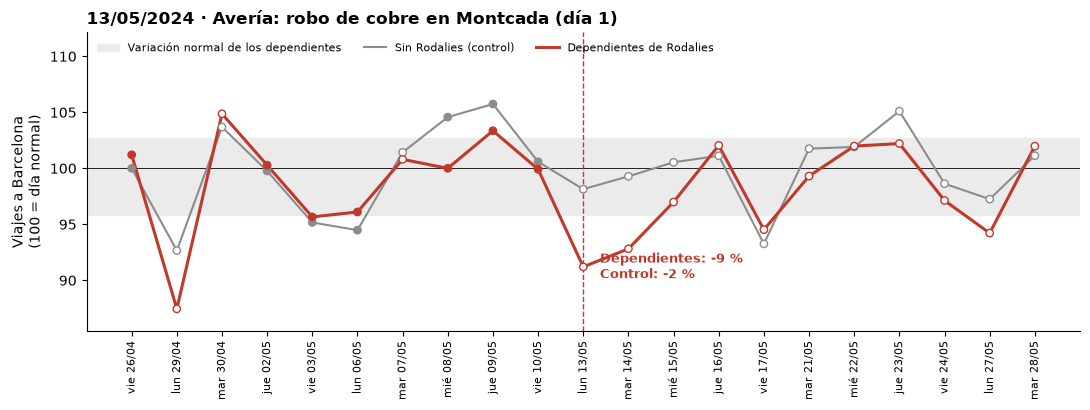

In [15]:
grafico_dia("2024-05-13")

**Qué se ve.** El 13/05/2024 la línea roja sale claramente de la franja de variación normal, mientras que
la gris se mantiene cerca de 100. Al día siguiente los dependientes vuelven a la normalidad.

### 1.2 Huelga del 17/03/2025

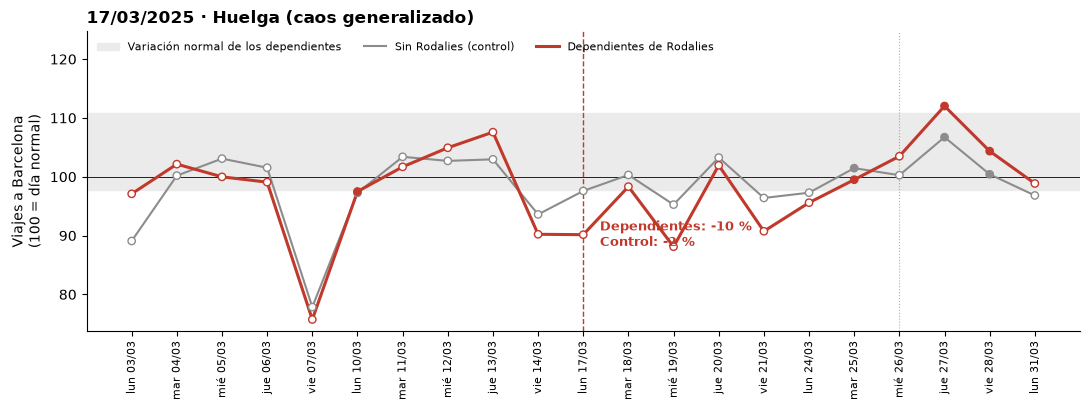

In [16]:
grafico_dia("2025-03-17")

**Qué se ve.** Misma imagen: el día de la huelga caen los dependientes y el control no. Las líneas
punteadas suaves marcan las otras jornadas de huelga (26/03 y 01/04).

## 2. ¿Cuántos viajes se pierden?

Un porcentaje es difícil de imaginar, así que lo pasamos a número de viajes:

1. **Viajes en un día normal:** viajes de los dependientes en los días limpios parecidos (mismo tipo de día).
2. **Viajes el día de caos:** el día normal menos el efecto de la incidencia (ya descontado lo que le pasó
   a todo el mundo ese día).
3. **Viajes perdidos** = la diferencia.

*Son viajes estimados por Telefónica (segmentos Regional y Residente) con cualquier medio de transporte.*

,incidencia,viajes_dia_normal,cambio_%,viajes_perdidos,claro
fecha,,,,,
13/05/2024,Avería: robo de cobre en Montcada (día 1),73400.0,-10.3,7600.0,True
17/03/2025,Huelga (caos generalizado),71200.0,-8.9,6300.0,True
26/03/2025,Huelga 24 h,71200.0,1.8,-1300.0,False
01/04/2025,Huelga 24 h,71200.0,-6.8,4800.0,True


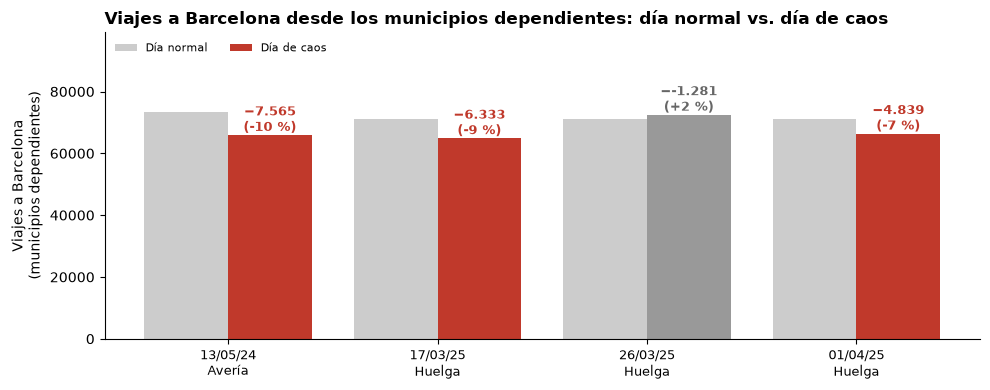

De media, cada día de caos los municipios dependientes hacen ≈ 4.364 viajes menos a Barcelona (de ≈ 71.732 en un día normal).


In [17]:
filas = []
for d in caos_real:
    f = comparar({"Dependientes": DEP}, [d]).iloc[0]
    normal = viajes_normales(DEP, d)
    filas.append({"fecha": d, "incidencia": DIAS_CAOS[d.strftime("%Y-%m-%d")],
                  "viajes_dia_normal": normal, "cambio_%": f["cambio_%"],
                  "viajes_perdidos": -normal * f["cambio_%"] / 100, "claro": (f["p"] < 0.05) and (f["cambio_%"] < 0)})
perdidos = pd.DataFrame(filas)
display(perdidos.set_index(perdidos.fecha.dt.strftime("%d/%m/%Y")).drop(columns="fecha")
        .round({"viajes_dia_normal": -2, "cambio_%": 1, "viajes_perdidos": -2}))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(perdidos))
caos_v = perdidos.viajes_dia_normal * (1 + perdidos["cambio_%"] / 100)
ax.bar(x - .2, perdidos.viajes_dia_normal, .4, color="0.8", label="Día normal")
ax.bar(x + .2, caos_v, .4, color=np.where(perdidos.claro, ROJO, "0.6"), label="Día de caos")
for xi, (_, r), v in zip(x, perdidos.iterrows(), caos_v):
    ax.text(xi + .2, v, f"−{miles(r.viajes_perdidos)}\n({r['cambio_%']:+.0f} %)", ha="center", va="bottom",
            fontsize=9, fontweight="bold", color=ROJO if r.claro else "0.4")
ax.set_xticks(x); ax.set_xticklabels([ETQ[d] for d in perdidos.fecha], fontsize=9)
ax.set_ylabel("Viajes a Barcelona\n(municipios dependientes)")
ax.set_ylim(0, perdidos.viajes_dia_normal.max() * 1.35)
ax.set_title("Viajes a Barcelona desde los municipios dependientes: día normal vs. día de caos",
             loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

print(f"De media, cada día de caos los municipios dependientes hacen ≈ {miles(perdidos.viajes_perdidos.mean())} "
      f"viajes menos a Barcelona (de ≈ {miles(perdidos.viajes_dia_normal.mean())} en un día normal).")

**Qué se ve.** Cada día de caos con un efecto claro, los municipios dependientes hacen **miles de viajes menos**
a Barcelona: ≈ **7.600** el 13/05/2024 (−10,3 %), ≈ **6.300** el 17/03/2025 (−8,9 %) y ≈ **4.800** el 01/04/2025 (−6,8 %),
de unos 71.000–73.000 en un día normal. El 26/03/2025 no hay caída (+1,8 %, no se distingue del ruido). De media,
≈ **4.400 viajes menos** por día de caos. Es una parte pequeña del total: la mayoría de la gente sigue viajando
(cambiando de ruta o de medio), pero una parte deja de ir (teletrabajo, aplaza el viaje).

## 3. ¿Quién nota el caos?

### 3.1 Según la alternativa que tiene cada municipio

Cada punto es el efecto medio de los 4 días de caos en un grupo de municipios; la barra es el margen de error.

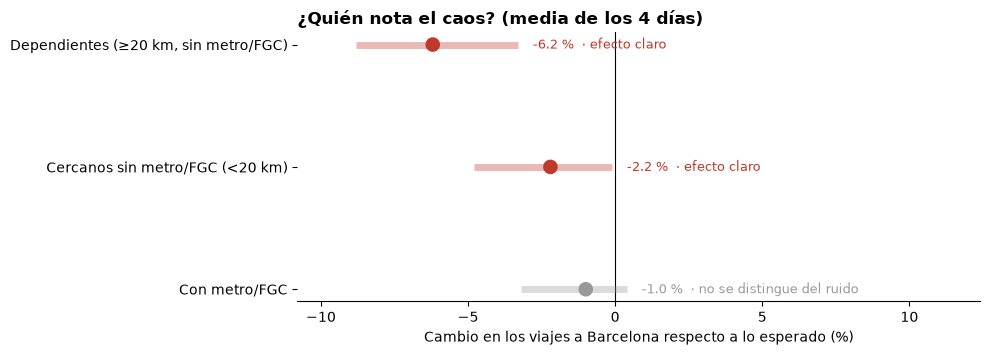

In [18]:
grupos = {"Dependientes (≥20 km, sin metro/FGC)": info.index[info.dependiente],
          "Cercanos sin metro/FGC (<20 km)": info.index[info.grupo == "Cercano sin metro/FGC"],
          "Con metro/FGC": info.index[info.con_alt]}
res_grupos = comparar(grupos, caos_real)
grafico_efectos(res_grupos, "¿Quién nota el caos? (media de los 4 días)")

**Resultado.** Solo los municipios **dependientes** tienen una caída clara y grande (**−6,2 %**, margen de error
[−8,8, −3,3]). Los cercanos sin metro/FGC caen un poco (**−2,2 %**): es pequeña, pero se distingue del ruido (p = 0,02),
sobre todo por las huelgas del 26/03 y el 01/04. Tienen bus metropolitano, pero lo notan algo. Los que tienen metro
o FGC no cambian (−1,0 %, no se distingue del ruido).

### 3.2 Según la distancia a Barcelona

Solo municipios con Rodalies y sin metro/FGC, agrupados por distancia.

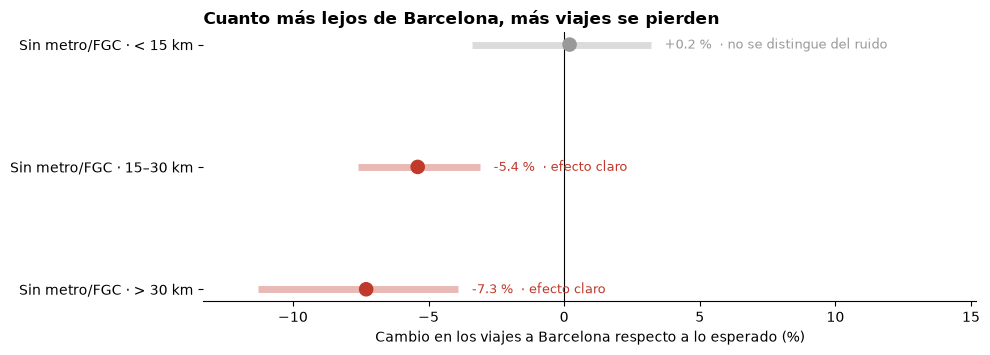

In [19]:
sin_alt = info[info.rodalies & ~info.con_alt]
bandas = pd.cut(sin_alt.dist_km, [0, 15, 30, 200], labels=["< 15 km", "15–30 km", "> 30 km"])
res_dist = comparar({f"Sin metro/FGC · {b}": sin_alt.index[bandas == b] for b in bandas.cat.categories}, caos_real)
grafico_efectos(res_dist, "Cuanto más lejos de Barcelona, más viajes se pierden")

**Resultado.** El efecto crece con la distancia: ≈ 0 % a menos de 15 km, **−5,4 %** entre 15 y 30 km
y **−7,3 % a más de 30 km** (las dos últimas, claras). Cuanto más lejos, más difícil es encontrar otra forma de
llegar y más gente renuncia al viaje.

## 4. ¿Qué pasa en cada línea?

Cada incidencia es distinta: una avería corta una línea concreta y una huelga afecta a toda la red de
forma desigual. Por eso se repite el cálculo **para los municipios dependientes de cada línea y cada día
de caos** por separado.

*Granollers y Les Franqueses tienen R2 Nord y R3, así que forman su propio grupo («R2N+R3»).*

In [20]:
# Efecto, margen de error y viajes perdidos para cada línea × día de caos
lineas_dep = sorted(dep.lineas.unique())
filas = []
for d in caos_real:
    tab = ic(comparar({l: dep.index[dep.lineas == l] for l in lineas_dep}, [d]))
    for l, f in tab.iterrows():
        normal = viajes_normales(dep.index[dep.lineas == l], d)
        filas.append({"fecha": d, "linea": l, "municipios": f.municipios,
                      "cambio_%": f["cambio_%"], "lo": f.lo, "hi": f.hi, "p": f["p"],
                      "viajes_dia_normal": normal, "viajes_perdidos": -normal * f["cambio_%"] / 100})
res_lineas = pd.DataFrame(filas)
res_lineas["claro"] = (res_lineas.p < 0.05) & (res_lineas["cambio_%"] < 0)   # efecto claro = caída significativa
res_lineas.round(1).head(8)

C:\Users\marti\AppData\Local\Temp\ipykernel_32684\783741854.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  res_lineas.round(1).head(8)


,fecha,linea,municipios,cambio_%,lo,hi,p,viajes_dia_normal,viajes_perdidos,claro
0,2024-05-13,R1,12,-13.5,-18.7,-5.3,0.0,24144.0,3259.4,True
1,2024-05-13,R2N,4,5.9,-3.1,20.3,0.9,4867.0,-287.2,False
2,2024-05-13,R2N+R3,2,-5.3,-12.2,3.2,0.1,8921.0,472.8,False
3,2024-05-13,R2S,4,-8.6,-16.6,2.8,0.1,23095.0,1986.2,False
4,2024-05-13,R3,5,-28.2,-50.0,-5.5,0.0,6815.0,1921.8,True
5,2024-05-13,R4,8,-5.2,-19.5,8.1,0.2,5691.0,295.9,False
6,2025-03-17,R1,12,-7.7,-13.2,1.1,0.0,24069.0,1853.3,True
7,2025-03-17,R2N,4,-11.2,-18.7,0.9,0.0,5277.0,591.0,True


### 4.1 ¿Baja el volumen total de viajes de cada línea?

Ahora sumamos los viajes a Barcelona de **todos los municipios de cada línea** (no solo los dependientes)
y miramos si ese total baja el día de caos.

Cada incidencia afecta a un tramo distinto, así que **solo se suman los municipios del tramo afectado**.
Por ejemplo, el 13/05/2024 (robo de cobre en Montcada) la R1 solo circulaba entre Badalona y Arenys,
así que se separa el tramo **sin tren** (norte de Arenys) del tramo **con transbordo** (hasta Arenys).
La R2 Sud funcionaba con normalidad: se muestra como **referencia** (no debería caer).
En las huelgas se usa toda la línea.

**Cómo se calcula:** viajes esperados = viajes del control ese día × proporción habitual entre la línea y
el control (días limpios del mismo año y mismo día de la semana). Así se descuenta lo que le pasó a todo
el mundo ese día. La **franja gris** es cuánto varía normalmente ese total en días sin incidencias.

In [21]:
# ── Qué tramo de cada línea afecta cada incidencia ─────────────────────────────
# Cada entrada: (etiqueta, línea, selector, afectada)
#   selector = "toda"                    → todos los municipios de la línea
#            = ("desde", "Municipio")    → municipios MÁS LEJOS de Barcelona que ese municipio
#            = ("hasta", "Municipio")    → municipios hasta ese municipio (incluido)
#            = ["Mun A", "Mun B", …]     → lista explícita
#   afectada = False → la línea funcionaba con normalidad: se muestra como REFERENCIA

R4_NORD = {"Montcada i Reixac", "Cerdanyola del Vallès", "Barberà del Vallès", "Sabadell", "Terrassa",
           "Viladecavalls", "Vacarisses", "Castellbell i el Vilar", "Sant Vicenç de Castellet", "Manresa", "Rajadell"}

# Municipios que están en la línea pero AL OTRO LADO de Barcelona (no usan ese corredor para llegar)
OTRO_LADO = {"R1":  {"Hospitalet de Llobregat, L'"},
             "R2N": {"Hospitalet de Llobregat, L'", "Prat de Llobregat, El"}}

EXCLUIR_CON_ALTERNATIVA = False   # True → quita los municipios con metro/FGC (Badalona, Sabadell, Terrassa…)

TRAMOS = {
    # Robo de cobre en Montcada (lunes, 2.º día). Fuente: Excel de incidencias + prensa.
    "2024-05-13": [
        ("R1 · norte de Arenys (sin tren)",           "R1",      ("desde", "Arenys de Mar"), True),
        ("R1 · hasta Arenys (transbordo en Badalona)", "R1",      ("hasta", "Arenys de Mar"), True),
        ("R3 · solo hasta Montcada Ripollet",          "R3",      "toda", True),
        ("R4 Nord · solo hasta Cerdanyola",            "R4 Nord", "toda", True),
        ("R4 Sud · solo hasta L'Hospitalet",           "R4 Sud",  "toda", True),
        ("R7 · sin servicio",                          "R7",      "toda", True),
        ("R2 Nord · casi toda la red (verificar)",     "R2N",     "toda", True),
        ("R2 Sud · funcionaba (referencia)",           "R2S",     "toda", False),
    ],
}
# Huelgas: afectan a toda la red → toda la línea
LINEAS_TRAMO = ["R1", "R2N", "R2S", "R3", "R4 Nord", "R4 Sud", "R7"]
for f in ["2025-03-17", "2025-03-26", "2025-04-01"]:
    TRAMOS[f] = [(f"{l} · toda la línea", l, "toda", True) for l in LINEAS_TRAMO]

# Averías de una sola línea (sección 4.6): la línea cortada y, como referencia, la que funcionaba
TRAMOS["2023-05-02"] = [("R2 Sud · servicio reducido (Gavà)", "R2S", "toda", True),
                        ("R2 Nord · funcionaba (referencia)", "R2N", "toda", False)]
TRAMOS["2024-11-22"] = [("R4 Nord · robo de cobre Sabadell–Terrassa", "R4 Nord", "toda", True),
                        ("R4 Sud · funcionaba (referencia)", "R4 Sud", "toda", False)]

# Nota: el 01/04/2025 coincide además con averías en la R4 (Castellbisbal) y la R2 Nord (vía única La Llagosta).

In [22]:
# ── Funciones: municipios del tramo y efecto en el VOLUMEN TOTAL ──────────────
lm = lineas_mun.copy()        # municipios con Rodalies: nombre, líneas, distancia a Barcelona, alternativa

def municipios_tramo(linea, selector):
    """Códigos de los municipios del tramo (solo municipios con ≥ MIN_VIAJES viajes/día)."""
    base = linea.split()[0]                                   # "R4 Nord" → "R4"
    m = lm[lm.lineas.map(lambda s: base in s)]
    m = m[~m.municipio.isin(OTRO_LADO.get(base, set()))]
    if linea == "R4 Nord": m = m[m.municipio.isin(R4_NORD)]
    if linea == "R4 Sud":  m = m[~m.municipio.isin(R4_NORD)]
    if isinstance(selector, tuple):
        modo, ref = selector
        assert (lm.municipio == ref).any(), f"No encuentro el municipio '{ref}'"
        d0 = lm.loc[lm.municipio == ref, "dist_km"].iloc[0]
        m = m[m.dist_km > d0] if modo == "desde" else m[m.dist_km <= d0]
    elif isinstance(selector, list):
        m = m[m.municipio.isin(selector)]
    if EXCLUIR_CON_ALTERNATIVA:
        m = m[~m.con_alternativa]
    return list(m.sort_values("dist_km").index.intersection(info.index))


def efecto_volumen(codes, d):
    """Viajes totales del tramo el día d frente a lo esperado.

    Esperado = viajes del control ese día × proporción habitual tramo/control
               (mediana de los días limpios del mismo año y mismo día de la semana).
    Así se descuenta lo que le pasó a todo el mundo ese día (lluvia, día flojo…).
    """
    serie = V_all[codes].sum(axis=1)
    ratio = (serie / tot_ctrl).dropna()
    limpios = cal.index[cal.limpio & (cal.index.year == d.year)].intersection(ratio.index)
    habitual = ratio.loc[limpios].groupby(limpios.day_of_week).median()      # proporción por día de la semana
    normal = ratio.loc[limpios] / habitual.reindex(limpios.day_of_week).values - 1   # variación normal
    esperado = tot_ctrl.loc[d] * habitual[d.day_of_week]
    real = serie.loc[d]
    ef = real / esperado - 1
    return {"municipios": len(codes), "viajes_esperados": esperado, "viajes_reales": real,
            "viajes_perdidos": esperado - real, "cambio_%": ef * 100,
            "normal_lo": np.percentile(normal, 2.5) * 100, "normal_hi": np.percentile(normal, 97.5) * 100,
            "p": (np.sum(normal <= ef) + 1) / (len(normal) + 1)}

In [23]:
# ── Cálculo para cada día de caos y cada tramo ──────────────────────────────
filas = []
for fecha, tramos in TRAMOS.items():
    d = pd.Timestamp(fecha)
    if d not in caos_real:
        continue
    for etiqueta, linea, selector, afectada in tramos:
        codes = municipios_tramo(linea, selector)
        if not codes:
            print(f"⚠️ {fecha} · {etiqueta}: sin municipios"); continue
        filas.append({"fecha": d, "tramo": etiqueta, "afectada": afectada, **efecto_volumen(codes, d),
                      "lista_municipios": ", ".join(lm.loc[codes, "municipio"])})
vol_lineas = pd.DataFrame(filas)
vol_lineas["claro"] = (vol_lineas.p < 0.05) & (vol_lineas["cambio_%"] < 0)

display(vol_lineas.assign(fecha=vol_lineas.fecha.dt.strftime("%d/%m/%Y"))
        [["fecha", "tramo", "municipios", "viajes_esperados", "viajes_reales", "viajes_perdidos", "cambio_%", "p", "claro"]]
        .round({"viajes_esperados": -1, "viajes_reales": -1, "viajes_perdidos": -1, "cambio_%": 1, "p": 3}))

,fecha,tramo,municipios,viajes_esperados,viajes_reales,viajes_perdidos,cambio_%,p,claro
0,13/05/2024,R1 · norte de Arenys (sin tren),6,5760.0,4610.0,1150.0,-19.9,0.010,True
1,13/05/2024,R1 · hasta Arenys (transbordo en Badalona),11,122200.0,126430.0,-4230.0,3.5,0.918,False
2,13/05/2024,R3 · solo hasta Montcada Ripollet,11,50450.0,48540.0,1910.0,-3.8,0.143,False
3,13/05/2024,R4 Nord · solo hasta Cerdanyola,10,77130.0,77850.0,-720.0,0.9,0.653,False
4,13/05/2024,R4 Sud · solo hasta L'Hospitalet,12,183050.0,189870.0,-6820.0,3.7,0.959,False
5,13/05/2024,R7 · sin servicio,2,31730.0,32780.0,-1050.0,3.3,0.714,False
6,13/05/2024,R2 Nord · casi toda la red (verificar),10,43180.0,43040.0,140.0,-0.3,0.449,False
7,13/05/2024,R2 Sud · funcionaba (referencia),8,197980.0,203870.0,-5900.0,3.0,0.827,False
8,17/03/2025,R1 · toda la línea,17,130410.0,124840.0,5580.0,-4.3,0.035,True
9,17/03/2025,R2N · toda la línea,10,43590.0,44890.0,-1300.0,3.0,0.807,False


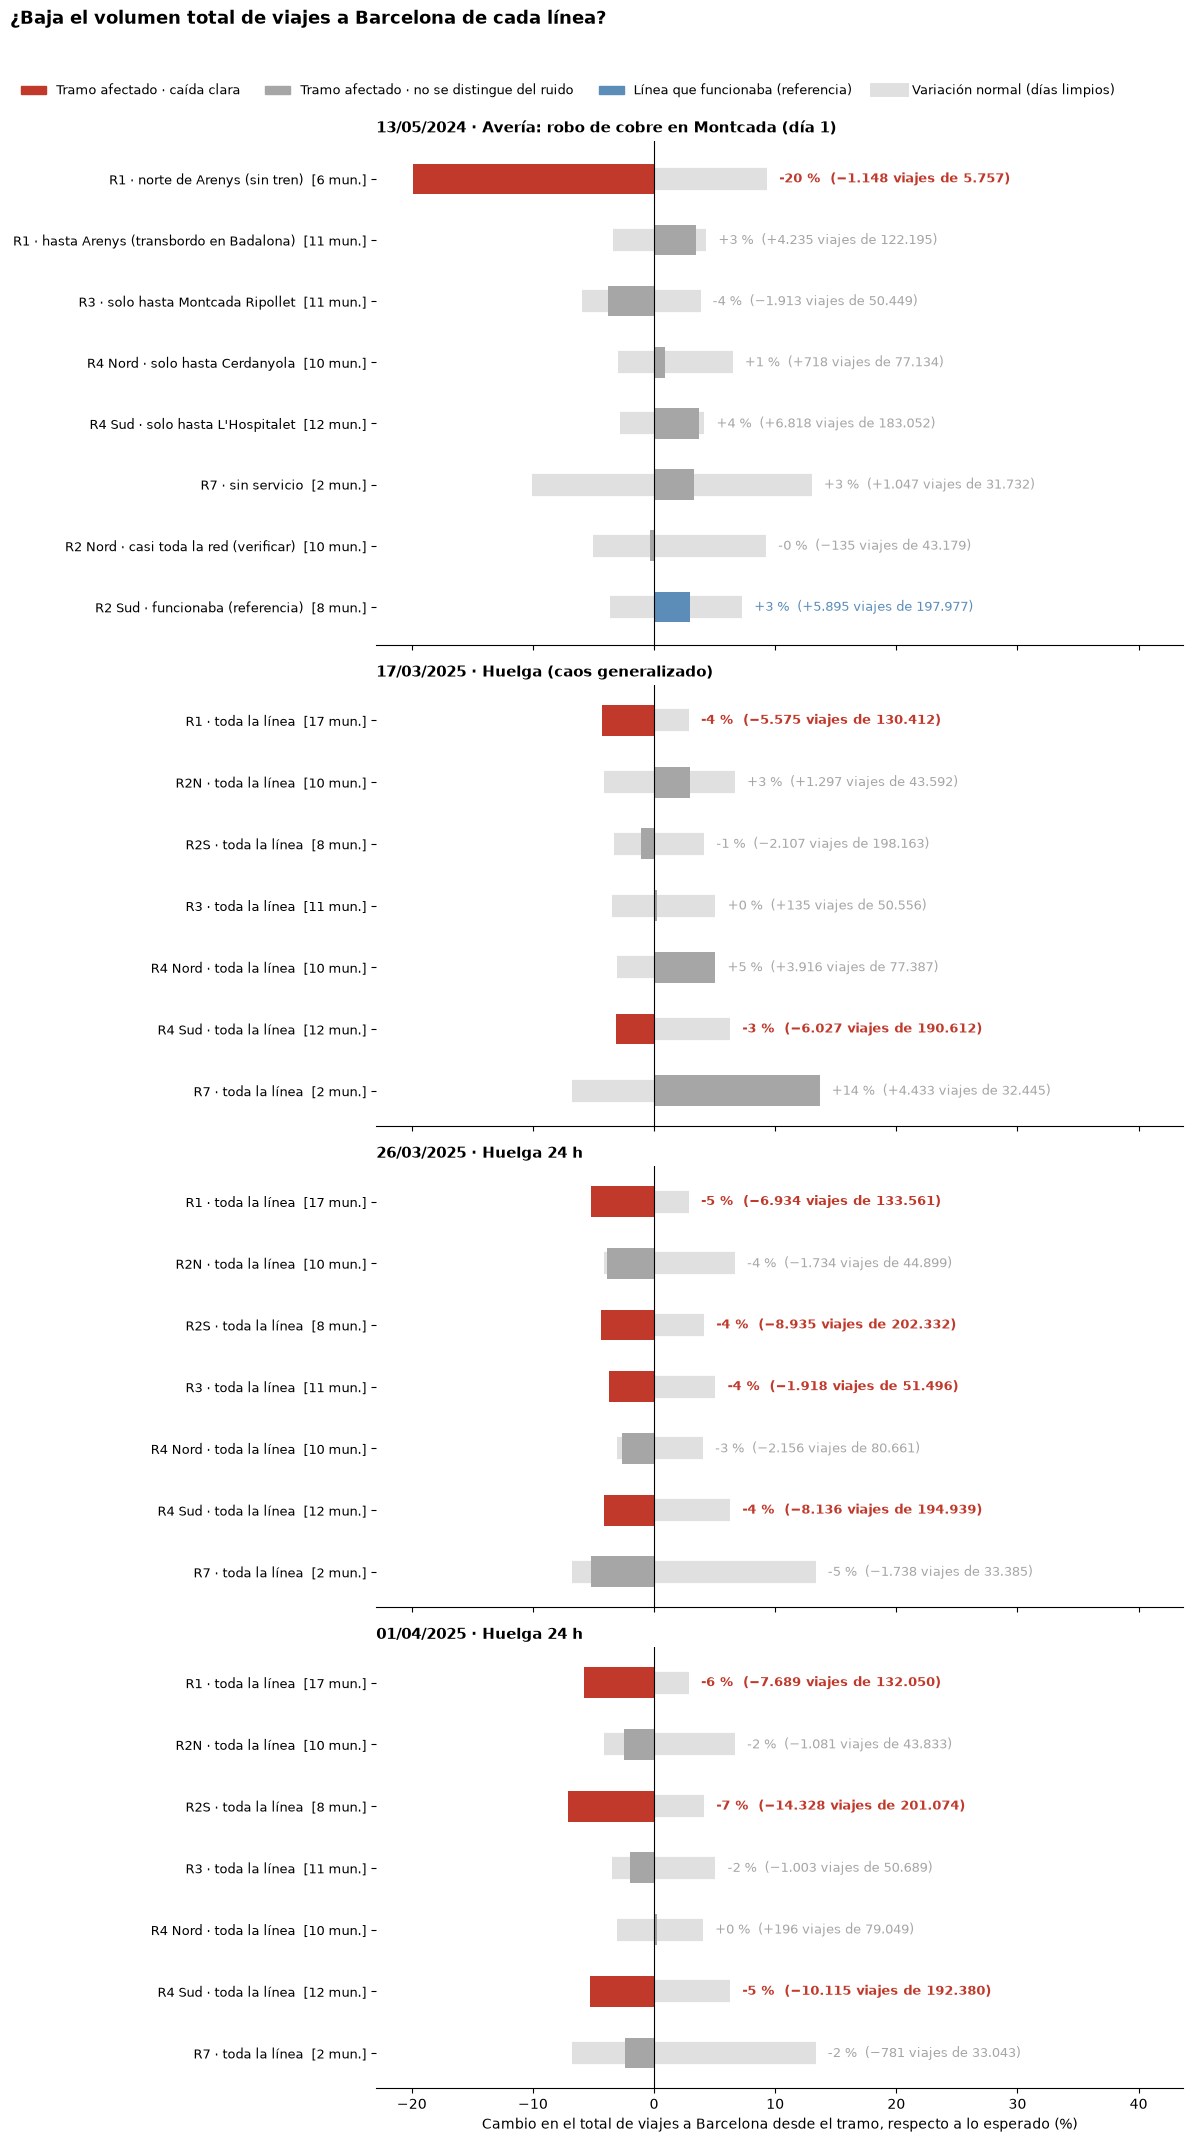

In [24]:
# ── Gráfico: un panel por día de caos, una barra por tramo ──────────────────
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

AZUL = "#5B8DB8"
dias = sorted(vol_lineas.fecha.unique())
alturas = [vol_lineas.fecha.eq(d).sum() for d in dias]
fig, axes = plt.subplots(len(dias), 1, figsize=(12, 0.55 * sum(alturas) + 1.2 * len(dias)),
                         gridspec_kw={"height_ratios": alturas}, sharex=True)
for ax, d in zip(np.atleast_1d(axes), dias):
    s = vol_lineas[vol_lineas.fecha == d].iloc[::-1]
    y = np.arange(len(s))
    ax.hlines(y, s.normal_lo, s.normal_hi, color="0.88", lw=16, zorder=0)       # variación normal
    col = np.where(~s.afectada, AZUL, np.where(s.claro, ROJO, "0.65"))
    ax.barh(y, s["cambio_%"], color=col, height=.5, zorder=2)
    ax.axvline(0, color="black", lw=.8)
    for yi, (_, r), c in zip(y, s.iterrows(), col):
        signo = "−" if r.viajes_perdidos > 0 else "+"
        ax.text(max(r["cambio_%"], r.normal_hi, 0) + 1, yi,
                f"{r['cambio_%']:+.0f} %  ({signo}{miles(abs(r.viajes_perdidos))} viajes de {miles(r.viajes_esperados)})",
                va="center", fontsize=9, color=c, fontweight="bold" if (r.claro and r.afectada) else "normal")
    ax.set_yticks(y); ax.set_yticklabels([f"{t}  [{n} mun.]" for t, n in zip(s.tramo, s.municipios)], fontsize=9)
    ax.set_title(f"{pd.Timestamp(d):%d/%m/%Y} · {DIAS_CAOS[pd.Timestamp(d).strftime('%Y-%m-%d')]}",
                 loc="left", fontweight="bold", fontsize=11)
    ax.spines[["top", "right", "left"]].set_visible(False)
lim = vol_lineas[["cambio_%", "normal_lo"]].min().min()
ax.set_xlim(lim - 3, vol_lineas[["cambio_%", "normal_hi"]].max().max() + 30)
ax.set_xlabel("Cambio en el total de viajes a Barcelona desde el tramo, respecto a lo esperado (%)")
fig.legend(handles=[Patch(color=ROJO, label="Tramo afectado · caída clara"),
                    Patch(color="0.65", label="Tramo afectado · no se distingue del ruido"),
                    Patch(color=AZUL, label="Línea que funcionaba (referencia)"),
                    Line2D([], [], color="0.88", lw=10, label="Variación normal (días limpios)")],
           loc="upper left", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.01, 1.0))
fig.suptitle("¿Baja el volumen total de viajes a Barcelona de cada línea?", x=0.01, y=1.03, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

**Cómo leerlo.** Cada panel es un día de caos y cada barra, un tramo de línea. La barra es cuánto cambia
el total de viajes a Barcelona desde ese tramo; a la derecha, cuántos viajes son.
**Rojo** = el tramo afectado cae más de lo normal. **Gris** = cae, pero dentro de la variación habitual.
**Azul** = línea que funcionaba ese día (sirve de comprobación: no debería caer).

**Resultado.**
- **Avería del 13/05/2024:** solo cae el tramo de la R1 **al norte de Arenys, sin tren** (**−20 %**, ≈ 1.200 viajes menos).
  El tramo hasta Arenys (con transbordo en Badalona), la R3, la R4 y la R7 no cambian en el total. La R2 Sud, que
  funcionaba, tampoco (+3 %) ✓.
- **Huelga del 17/03/2025:** caen un poco la R1 (−4 %) y la R4 Sud (−3 %).
- **Huelgas del 26/03 y el 01/04/2025:** caen varias líneas a la vez, entre −4 % y −7 %. La mayor caída en viajes es la
  del **Garraf (R2 Sud) el 01/04: −7 %, ≈ 14.000 viajes menos**.

**A tener en cuenta.** Al sumar todos los municipios, pesan mucho los grandes (Mataró, Sabadell, Terrassa…),
que a menudo tienen alternativas (metro, FGC, bus). Por eso los porcentajes son más pequeños que en los
municipios dependientes (sección 4.2). Los municipios con varias líneas (Granollers, Mollet, Montcada…)
cuentan en cada una de ellas.

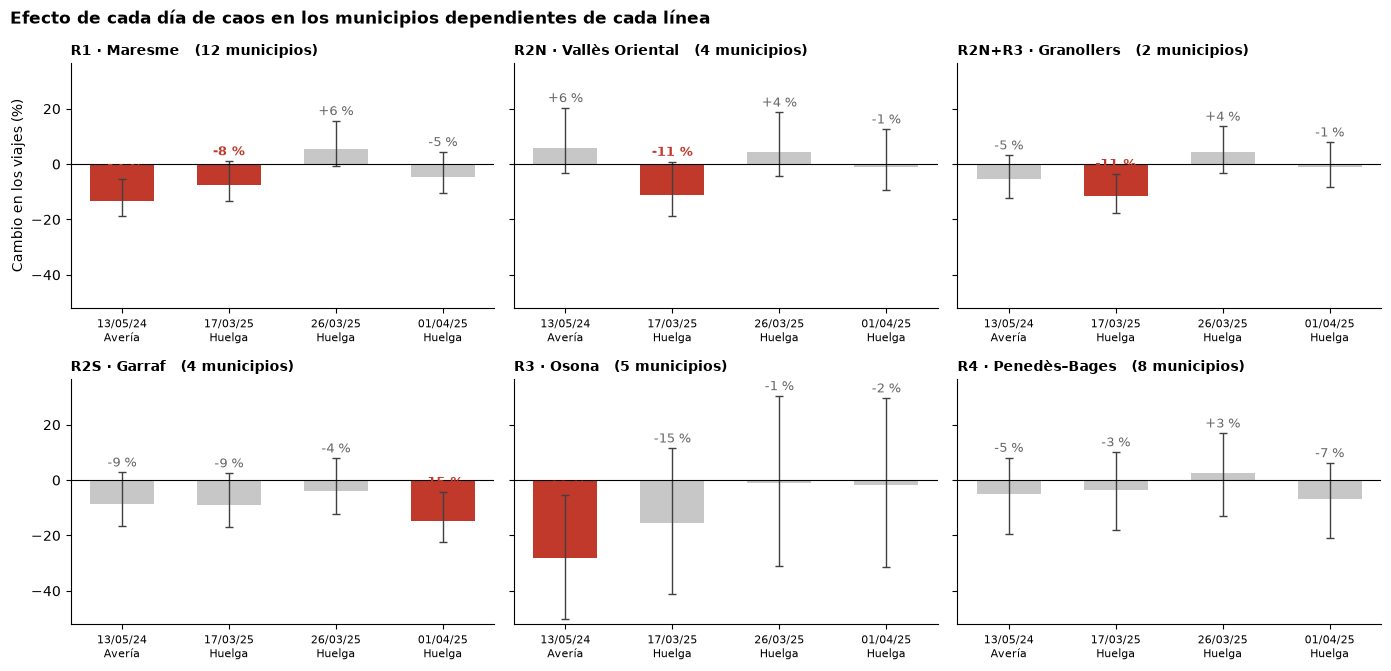

In [25]:
n = len(lineas_dep); ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.4 * nrow), sharey=True)
for ax, l in zip(axes.flat, lineas_dep):
    s = res_lineas[res_lineas.linea == l].sort_values("fecha")
    x = np.arange(len(s))
    ax.bar(x, s["cambio_%"], color=np.where(s.claro, ROJO, "0.78"), width=.6)
    ax.errorbar(x, s["cambio_%"], yerr=[s["cambio_%"] - s.lo, s.hi - s["cambio_%"]],
                fmt="none", ecolor="0.25", capsize=3, lw=1)
    for xi, (_, r) in zip(x, s.iterrows()):
        ax.text(xi, r.hi + 1, f"{r['cambio_%']:+.0f} %", ha="center", va="bottom", fontsize=9,
                fontweight="bold" if r.claro else "normal", color=ROJO if r.claro else "0.4")
    ax.axhline(0, color="black", lw=.8)
    ax.set_title(f"{l} · {NOMBRE_LINEA.get(l, '')}   ({s.municipios.iloc[0]} municipios)",
                 loc="left", fontweight="bold", fontsize=10)
    ax.set_xticks(x); ax.set_xticklabels([ETQ[d] for d in s.fecha], fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes.flat[n:]:
    ax.axis("off")
axes.flat[0].set_ylim(res_lineas.lo.min() - 2, res_lineas.hi.max() + 6)   # eje compartido
axes.flat[0].set_ylabel("Cambio en los viajes (%)")
fig.suptitle("Efecto de cada día de caos en los municipios dependientes de cada línea",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()

### 4.2 Ficha de cada línea

Resumen automático: qué municipios dependen de cada línea, cuántos viajes hacen en un día normal y qué
días caen de forma clara.

In [26]:
txt = []
for l in lineas_dep:
    s = res_lineas[res_lineas.linea == l].sort_values("fecha")
    muns = dep[dep.lineas == l].sort_values("dist_km")
    claros = s[s.claro]
    if claros.empty:
        res = "**No cae de forma clara en ningún día de caos.**"
    else:
        res = "**Cae claramente** " + "; ".join(
            f"el {r.fecha:%d/%m/%Y} ({r['cambio_%']:+.0f} %, ≈ {miles(r.viajes_perdidos)} viajes menos)"
            for _, r in claros.iterrows()) + "."
    txt.append(f"#### {l} · {NOMBRE_LINEA.get(l, '')}\n"
               f"- {len(muns)} municipios dependientes, de {muns.municipio.iloc[0]} ({muns.dist_km.iloc[0]:.0f} km) "
               f"a {muns.municipio.iloc[-1]} ({muns.dist_km.iloc[-1]:.0f} km): {', '.join(muns.municipio)}.\n"
               f"- ≈ {miles(s.viajes_dia_normal.median())} viajes a Barcelona en un día normal.\n"
               f"- {res}\n")
display(Markdown("\n".join(txt)))

#### R1 · Maresme
- 12 municipios dependientes, de Vilassar de Mar (22 km) a Tordera (58 km): Vilassar de Mar, Cabrera de Mar, Mataró, Sant Andreu de Llavaneres, Caldes d'Estrac, Arenys de Mar, Canet de Mar, Sant Pol de Mar, Calella, Pineda de Mar, Malgrat de Mar, Tordera.
- ≈ 24.069 viajes a Barcelona en un día normal.
- **Cae claramente** el 13/05/2024 (-14 %, ≈ 3.259 viajes menos); el 17/03/2025 (-8 %, ≈ 1.853 viajes menos).

#### R2N · Vallès Oriental
- 4 municipios dependientes, de Cardedeu (32 km) a Sant Celoni (43 km): Cardedeu, Llinars del Vallès, Santa Maria de Palautordera, Sant Celoni.
- ≈ 5.277 viajes a Barcelona en un día normal.
- **Cae claramente** el 17/03/2025 (-11 %, ≈ 591 viajes menos).

#### R2N+R3 · Granollers
- 2 municipios dependientes, de Granollers (26 km) a Franqueses del Vallès, Les (28 km): Granollers, Franqueses del Vallès, Les.
- ≈ 9.354 viajes a Barcelona en un día normal.
- **Cae claramente** el 17/03/2025 (-11 %, ≈ 1.066 viajes menos).

#### R2S · Garraf
- 4 municipios dependientes, de Castelldefels (21 km) a Cubelles (46 km): Castelldefels, Sitges, Vilanova i la Geltrú, Cubelles.
- ≈ 21.928 viajes a Barcelona en un día normal.
- **Cae claramente** el 01/04/2025 (-15 %, ≈ 3.245 viajes menos).

#### R3 · Osona
- 5 municipios dependientes, de Garriga, La (34 km) a Manlleu (69 km): Garriga, La, Centelles, Balenyà, Vic, Manlleu.
- ≈ 5.134 viajes a Barcelona en un día normal.
- **Cae claramente** el 13/05/2024 (-28 %, ≈ 1.922 viajes menos).

#### R4 · Penedès–Bages
- 8 municipios dependientes, de Viladecavalls (26 km) a Sant Vicenç de Castellet (40 km): Viladecavalls, Gelida, Sant Sadurní d'Anoia, Vacarisses, Subirats, Castellbell i el Vilar, Vilafranca del Penedès, Sant Vicenç de Castellet.
- ≈ 5.535 viajes a Barcelona en un día normal.
- **No cae de forma clara en ningún día de caos.**


### 4.3 Todo de un vistazo

La misma información en una sola tabla de colores: filas = días de caos, columnas = líneas.
**Rojo = caen los viajes; en negrita = efecto claro.**

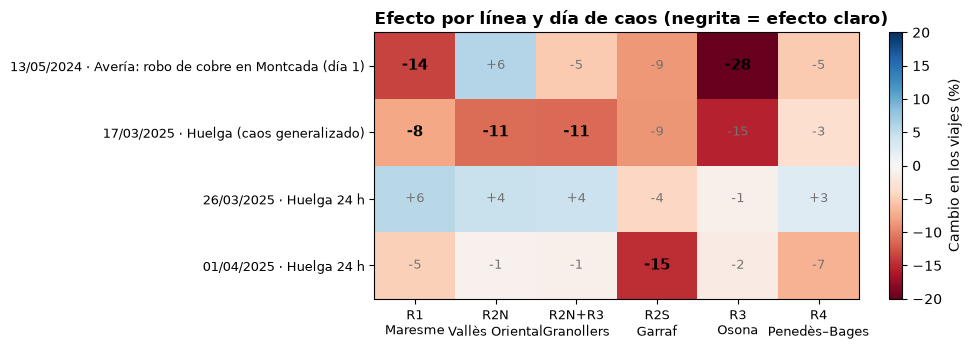

In [27]:
tabla_dias = res_lineas.pivot(index="fecha", columns="linea", values="cambio_%")
signif = res_lineas.pivot(index="fecha", columns="linea", values="claro")
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(tabla_dias.values, cmap="RdBu", vmin=-20, vmax=20, aspect="auto")
for i in range(tabla_dias.shape[0]):
    for j in range(tabla_dias.shape[1]):
        claro = signif.iat[i, j]
        ax.text(j, i, f"{tabla_dias.iat[i, j]:+.0f}", ha="center", va="center",
                fontsize=11 if claro else 9, fontweight="bold" if claro else "normal",
                color="black" if claro else "0.45")
ax.set_xticks(range(tabla_dias.shape[1]), [f"{l}\n{NOMBRE_LINEA.get(l, '')}" for l in tabla_dias.columns], fontsize=9)
ax.set_yticks(range(tabla_dias.shape[0]),
              [f"{d:%d/%m/%Y} · {DIAS_CAOS[d.strftime('%Y-%m-%d')]}" for d in tabla_dias.index], fontsize=9)
plt.colorbar(im, label="Cambio en los viajes (%)")
ax.set_title("Efecto por línea y día de caos (negrita = efecto claro)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Resultado.**

- **R1 (Maresme)** es la más afectada el día de la avería (**−14 %**), cuando solo circulaba entre Badalona
  y Arenys, y también cae en la huelga del 17/03 (**−8 %**).
- **R3 (Osona)** cae **−28 %** el día de la avería, cuando solo llegaba hasta Montcada, aunque con un margen de error
  muy amplio (solo 5 municipios). El 17/03 cae −15 %, al límite (p = 0,05).
- **R2 Nord y Granollers (R2N+R3)** caen el 17/03 (**≈ −11 %**).
- **R2 Sud (Garraf)** cae claramente el 01/04 (**−15 %**); el 17/03 cae −9 % (al límite, p = 0,05) y el 26/03, −4 %
  (no se distingue del ruido). *Con la regresión, el Garraf caía ≈ −17 % en las tres huelgas: este resultado depende
  del método.* El 13/05, cuando la R2 Sud funcionaba con normalidad, da −9 % (p = 0,05), también al límite.
- **R4** no cae claramente ningún día.
- **El 26/03 ninguna línea cae claramente.** En M3 se ve que ese día los viajes se redistribuyen entre barrios.

**Conclusión.** En una **avería**, cae la línea cortada (R1 y R3 el 13/05/2024). En las **huelgas**, el 17/03/2025
(caos generalizado) caen casi todos los corredores; en las huelgas anunciadas el efecto es menor y desigual, y el
Garraf es el corredor más afectado el 01/04.

### 4.4 Dos días en detalle: municipio a municipio

Para los dos días de caos más claros, se muestra cada municipio sobre su línea:

- **Esquema de líneas:** cada fila es una línea de Rodalies y cada punto, un municipio situado según su
  distancia a Barcelona. Color = cambio de viajes (rojo = caída), tamaño = volumen y borde negro = efecto claro.
- **Los 10 municipios que más caen**, con su p.

#### Huelga del 17/03/2025
Huelga de los sindicatos minoritarios contra el traspaso de Rodalies: retrasos y supresiones en toda la red.

2025-03-17 · Huelga (caos generalizado)


,municipios,cambio_%,margen_error_95,p
grupo,,,,
Dependientes,35,-8.9,"[-13.3, -3.0]",0.011
Con alternativa (cercanos o con metro/FGC),27,0.1,"[-3.1, 2.9]",0.579


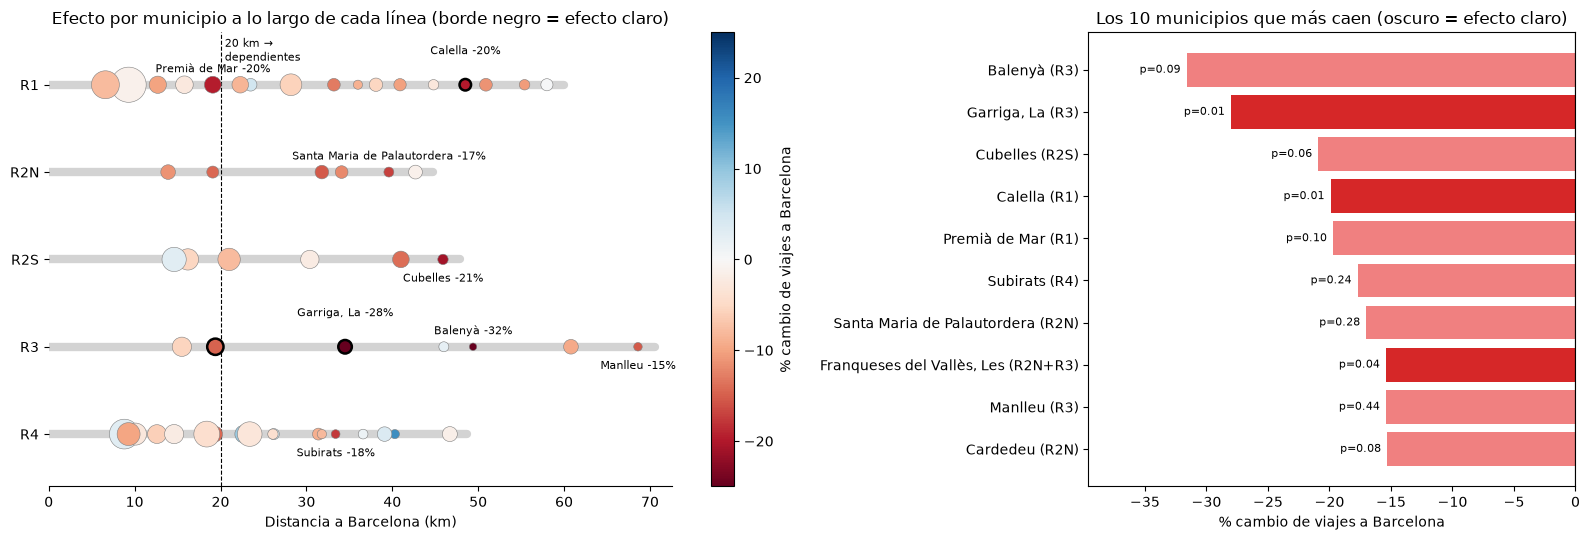

,municipio,lineas,dist_km,viajes_dia,efecto_%,z,p
0,Balenyà,R3,49.0,134.0,-31.6,-1.90,0.088
1,"Garriga, La",R3,34.0,1450.0,-28.0,-3.57,0.007
2,Cubelles,R2S,46.0,503.0,-20.9,-2.22,0.059
3,Calella,R1,48.0,763.0,-19.9,-2.65,0.015
4,Premià de Mar,R1,19.0,3478.0,-19.7,-2.15,0.103
5,Subirats,R4,33.0,256.0,-17.7,-0.92,0.242
6,Santa Maria de Palautordera,R2N,40.0,420.0,-17.0,-1.21,0.278
7,"Franqueses del Vallès, Les",R2N+R3,28.0,1578.0,-15.4,-2.15,0.037
8,Manlleu,R3,69.0,225.0,-15.4,-0.79,0.440
9,Cardedeu,R2N,32.0,1476.0,-15.3,-1.91,0.081


In [28]:
r_17mar = estudio_dia("2025-03-17")

**Resultado.** Los dependientes caen **−8,9 %** (margen de error [−13,3, −3,0]) y los municipios con alternativa no
cambian (+0,1 %). La caída se reparte por los corredores alejados: Osona (La Garriga −28 %, Balenyà −32 %), el Maresme
norte (Calella −20 %), el Garraf (Cubelles −21 %) y Granollers (Les Franqueses −15 %). Municipio a municipio, solo
La Garriga, Calella y Les Franqueses son claros: los municipios pequeños varían mucho de un día a otro, por eso la
conclusión se basa en el grupo.

#### Avería del 13/05/2024 (robo de cobre en Montcada)

2024-05-13 · Avería: robo de cobre en Montcada (día 1)


,municipios,cambio_%,margen_error_95,p
grupo,,,,
Dependientes,35,-10.3,"[-14.7, -4.6]",0.007
Con alternativa (cercanos o con metro/FGC),27,3.2,"[-0.2, 6.1]",0.956


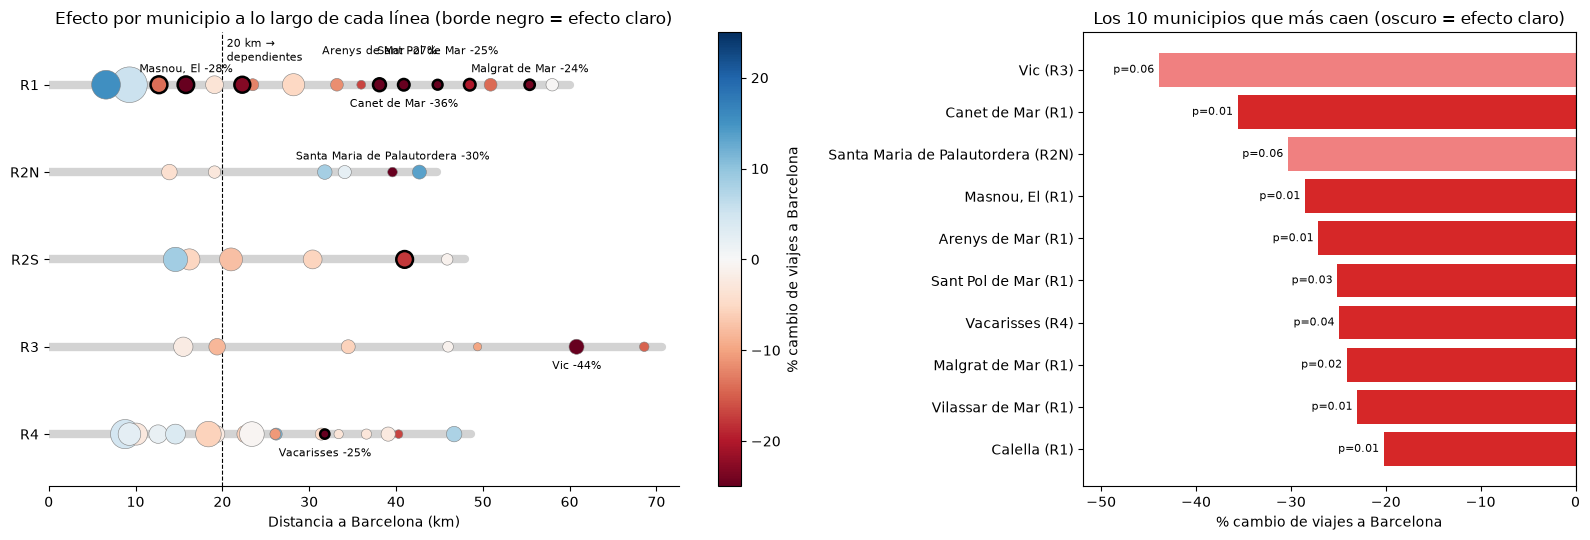

,municipio,lineas,dist_km,viajes_dia,efecto_%,z,p
0,Vic,R3,61.0,2207.0,-43.9,-2.70,0.059
1,Canet de Mar,R1,41.0,761.0,-35.6,-5.70,0.007
2,Santa Maria de Palautordera,R2N,40.0,373.0,-30.3,-2.33,0.059
3,"Masnou, El",R1,16.0,3199.0,-28.5,-3.69,0.007
4,Arenys de Mar,R1,38.0,1196.0,-27.1,-4.52,0.007
5,Sant Pol de Mar,R1,45.0,394.0,-25.1,-2.18,0.029
6,Vacarisses,R4,32.0,320.0,-24.9,-2.17,0.044
7,Malgrat de Mar,R1,55.0,488.0,-24.1,-2.45,0.022
8,Vilassar de Mar,R1,22.0,2739.0,-23.0,-4.69,0.007
9,Calella,R1,48.0,768.0,-20.2,-2.71,0.015


In [29]:
mun_13may = estudio_dia("2024-05-13")

**Resultado.** Los dependientes caen **−10,3 %** (margen de error [−14,7, −4,6]) y los municipios con alternativa no
cambian (+3,2 %, no se distingue del ruido). A diferencia de la huelga, la caída se concentra en **una sola línea, la R1
(Maresme)**: 7 de los 10 municipios que más caen son de esta línea, todos con un efecto claro (Canet −36 %, El Masnou
−28 %, Arenys −27 %, Sant Pol −25 %, Malgrat −24 %, Vilassar de Mar −23 %, Calella −20 %). Que los datos señalen justo la
línea cortada confirma el método.

Vic (R3) cae −44 %, aunque no llega a ser claro (p = 0,06): coherente con que ese día la R3 solo llegaba hasta Montcada.
Como los datos cuentan viajes con cualquier medio, el método mide los **viajes que dejan de hacerse**, no el cambio de medio.

### 4.5 Contraste: una avería grande pero corta (05/06/2025)

Según el registro oficial, el 05/06/2025 es la avería de Rodalies con más viajeros afectados
(≈ 39.300) entre los días que se pueden analizar (laborable, fuera de verano y sin lluvia): un tren
detenido entre Plaça Catalunya y la Bifurcació Vilanova bloqueó las líneas R1, R2, R3 y R4 entre las
**14:25 y las 16:14**.

Es un buen contraste con los días de caos: afecta a muchos viajeros, pero dura menos de dos horas y por
la tarde, cuando la mayoría ya ha llegado a Barcelona. **Si lo que reduce los viajes es quedarse sin tren
para ir, este día no debería mostrar caída.** No se incluye en las medias de las secciones 3 y 5.

Mal tiempo: False · lluvia: 0.2 mm


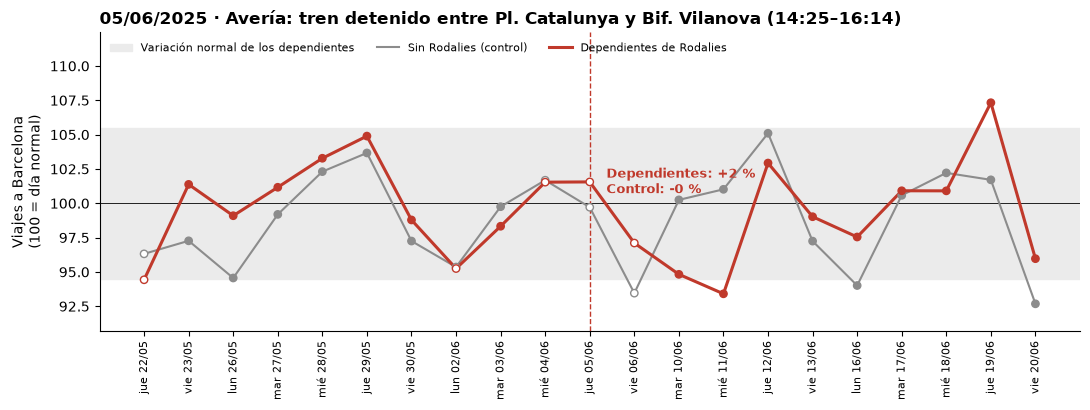

In [30]:
DIA_C, DESC_C = CASO_CONTRASTE
d_c = pd.Timestamp(DIA_C)
DIAS_CAOS[DIA_C] = DESC_C                       # para los títulos de los gráficos
print("Mal tiempo:", bool(cal.at[d_c, "mal_tiempo"]), "· lluvia:", round(cal.at[d_c, "lluvia_pond"], 1), "mm")
grafico_dia(DIA_C)

In [31]:
# Efecto por grupo y por línea (clustering), igual que en las secciones 3 y 4
t_grupo = comparar({"Dependientes": info.index[info.dependiente],
                    "Con alternativa (cercanos o con metro/FGC)": info.index[info.rodalies & ~info.dependiente]}, [d_c])
display(t_grupo[["municipios", "cambio_%", "IC95", "p"]].rename(columns={"IC95": "margen_error_95"}))

t_lin = ic(comparar({l: dep.index[dep.lineas == l] for l in lineas_dep}, [d_c]))
t_lin["claro"] = (t_lin["p"] < 0.05) & (t_lin["cambio_%"] < 0)
display(t_lin[["municipios", "cambio_%", "lo", "hi", "p", "claro"]].round(2))

,municipios,cambio_%,margen_error_95,p
grupo,,,,
Dependientes,35,0.0,"[-4.9, 6.4]",0.502
Con alternativa (cercanos o con metro/FGC),27,0.8,"[-2.5, 3.6]",0.685


,municipios,cambio_%,lo,hi,p,claro
grupo,,,,,,
R1,12,-1.3,-7.2,8.1,0.35,False
R2N,4,5.3,-3.7,19.6,0.84,False
R2N+R3,2,2.4,-5.0,11.6,0.71,False
R2S,4,-3.5,-11.9,8.5,0.20,False
R3,5,8.2,-24.6,42.5,0.86,False
R4,8,8.0,-8.3,23.2,0.87,False


**Resultado.** Los municipios dependientes **no caen** (**0,0 %**, margen de error [−4,9, +6,4]), a pesar de que es la
avería con más viajeros afectados del registro. Por línea, ninguna cae de forma clara (la que más, la R2 Sud, −3,5 %).

**Lectura.** El número de viajeros afectados no basta para predecir el impacto: una avería corta y por la tarde
retrasa a la gente, pero no hace que deje de ir a Barcelona. Lo que reduce los viajes es **quedarse sin servicio
para ir** (corte sin alternativa como el del 13/05/2024, o huelga).

### 4.6 Averías de una sola línea

Además de los días de caos, se analizan dos **averías que dejaron una sola línea sin servicio normal**:

| Fecha | Línea | Qué pasó |
|---|---|---|
| 02/05/2023 | R2 Sud (Garraf) | Primer día del incendio del enclavamiento de Gavà: servicio reducido (n.º 3 del ranking de prensa) |
| 22/11/2024 | R4 Nord (Vallès–Bages) | Robo de cobre entre Sabadell y Terrassa, con retrasos desde el inicio del servicio |

**Por qué aparte.** En una avería de una línea, los municipios de las demás líneas siguen teniendo tren: si se
mezclan, diluyen el efecto. Por eso se miden **solo los dependientes de la línea afectada** y, como comprobación,
los de las líneas que funcionaban (no deberían caer). No entran en las medias de los días de caos (secciones 2, 3 y 5).

*Salen de probar 18 averías importantes del registro oficial y de la prensa con este mismo método
(análisis exploratorio previo). En la mayoría no hay una caída clara, coherente con la sección 4.5: la
mayoría de las averías retrasan a la gente, pero no hacen que deje de ir a Barcelona.*

In [32]:
# Municipios dependientes de cada línea (la R4 se separa en Nord y Sud)
def lineas_dep_mun(r):
    ls = set(r.lineas.split("+"))
    if "R4" in ls:
        ls = (ls - {"R4"}) | {"R4N" if r.municipio in R4_NORD else "R4S"}
    return ls
dep_L = dep.apply(lineas_dep_mun, axis=1)

filas = []
for fecha, (linea, desc) in AVERIAS_LINEA.items():
    d = pd.Timestamp(fecha)
    afect = list(dep.index[dep_L.map(lambda s: linea in s)])
    resto = list(dep.index[dep_L.map(lambda s: linea not in s)])
    t = ic(comparar({"afectada": afect, "resto": resto}, [d]))
    a, r = t.loc["afectada"], t.loc["resto"]
    normal = viajes_normales(afect, d)
    filas.append({"fecha": d, "linea": linea, "incidencia": desc, "municipios": int(a.municipios),
                  "cambio_%": a["cambio_%"], "lo": a.lo, "hi": a.hi, "p": a["p"],
                  "viajes_dia_normal": normal, "viajes_perdidos": -normal * a["cambio_%"] / 100,
                  "regresión_%": a["regresión_%"], "resto_%": r["cambio_%"], "resto_p": r["p"]})
res_averias = pd.DataFrame(filas)
res_averias["claro"] = (res_averias.p < 0.05) & (res_averias["cambio_%"] < 0)
display(res_averias.assign(fecha=res_averias.fecha.dt.strftime("%d/%m/%Y")).drop(columns="incidencia")
        .round({"cambio_%": 1, "lo": 1, "hi": 1, "p": 3, "viajes_dia_normal": -1, "viajes_perdidos": -1,
                "regresión_%": 1, "resto_%": 1, "resto_p": 3}))

,fecha,linea,municipios,cambio_%,lo,hi,p,viajes_dia_normal,viajes_perdidos,regresión_%,resto_%,resto_p,claro
0,02/05/2023,R2S,4,-11.6,-19.3,-0.6,0.026,25060.0,2910.0,-16.8,-0.8,0.399,True
1,22/11/2024,R4N,4,-10.3,-24.1,1.2,0.044,1560.0,160.0,-17.5,-2.7,0.161,True


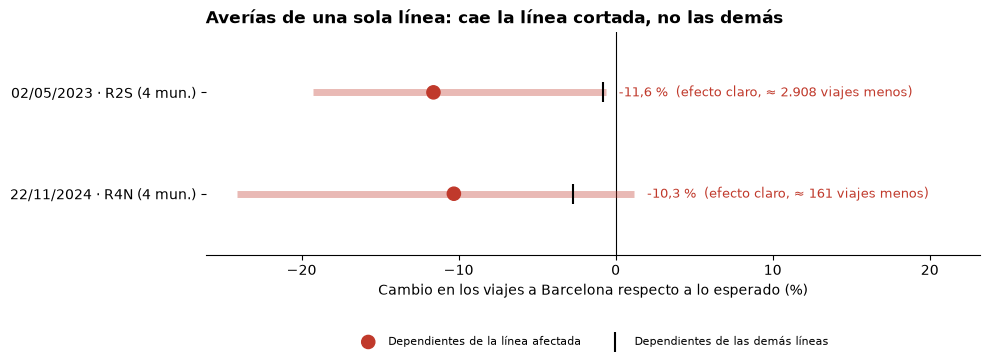

In [33]:
# Gráfico: efecto en la línea afectada (punto rojo, con margen de error) y en las demás líneas (marca negra)
t = res_averias.iloc[::-1].reset_index(drop=True)
y = np.arange(len(t))
col = np.where(t.claro, ROJO, "0.6")
fig, ax = plt.subplots(figsize=(10, 1.1 * len(t) + 1.8))
ax.axvline(0, color="black", lw=.8)
ax.hlines(y, t.lo, t.hi, color=col, lw=5, alpha=.35)
ax.scatter(t["cambio_%"], y, color=col, s=90, zorder=3, label="Dependientes de la línea afectada")
ax.scatter(t["resto_%"], y, marker="|", color="black", s=200, zorder=3, label="Dependientes de las demás líneas")
for yi, r in t.iterrows():
    ax.text(r.hi + .8, yi, f"{r['cambio_%']:+.1f} %".replace(".", ",") + f"  ({'efecto claro' if r.claro else 'no se distingue del ruido'}, "
                           f"≈ {miles(abs(r.viajes_perdidos))} viajes {'menos' if r.viajes_perdidos > 0 else 'más'})",
            va="center", fontsize=9, color=col[yi])
ax.set_yticks(y, [f"{r.fecha:%d/%m/%Y} · {r.linea} ({r.municipios} mun.)" for _, r in t.iterrows()])
ax.set_xlim(min(t.lo.min(), t["resto_%"].min(), 0) - 2, max(t.hi.max(), 0) + 22)
ax.set_xlabel("Cambio en los viajes a Barcelona respecto a lo esperado (%)")
ax.set_title("Averías de una sola línea: cae la línea cortada, no las demás", loc="left", fontweight="bold")
ax.set_ylim(-0.6, len(t) - 0.4)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout(); plt.show()

**Volumen total del tramo (mismo cálculo que la sección 4.1).** Todos los municipios de la línea, no solo los
dependientes; la línea que funcionaba ese día sirve de referencia.

In [34]:
filas = []
for fecha in AVERIAS_LINEA:
    d = pd.Timestamp(fecha)
    for etiqueta, linea, selector, afectada in TRAMOS[fecha]:
        codes = municipios_tramo(linea, selector)
        if codes:
            filas.append({"fecha": d, "tramo": etiqueta, "afectada": afectada, **efecto_volumen(codes, d)})
vol_averias = pd.DataFrame(filas)
vol_averias["claro"] = (vol_averias.p < 0.05) & (vol_averias["cambio_%"] < 0)
display(vol_averias.assign(fecha=vol_averias.fecha.dt.strftime("%d/%m/%Y"))
        [["fecha", "tramo", "municipios", "viajes_esperados", "viajes_reales", "viajes_perdidos", "cambio_%", "p", "claro"]]
        .round({"viajes_esperados": -1, "viajes_reales": -1, "viajes_perdidos": -1, "cambio_%": 1, "p": 3}))

,fecha,tramo,municipios,viajes_esperados,viajes_reales,viajes_perdidos,cambio_%,p,claro
0,02/05/2023,R2 Sud · servicio reducido (Gavà),8,207150.0,206860.0,290.0,-0.1,0.458,False
1,02/05/2023,R2 Nord · funcionaba (referencia),10,45770.0,44790.0,980.0,-2.1,0.300,False
2,22/11/2024,R4 Nord · robo de cobre Sabadell–Terrassa,10,83040.0,79640.0,3410.0,-4.1,0.020,True
3,22/11/2024,R4 Sud · funcionaba (referencia),12,191420.0,185750.0,5670.0,-3.0,0.020,True


**Cada avería vista directamente.** Como en la sección 1, pero la línea roja son solo los dependientes de la
línea afectada.

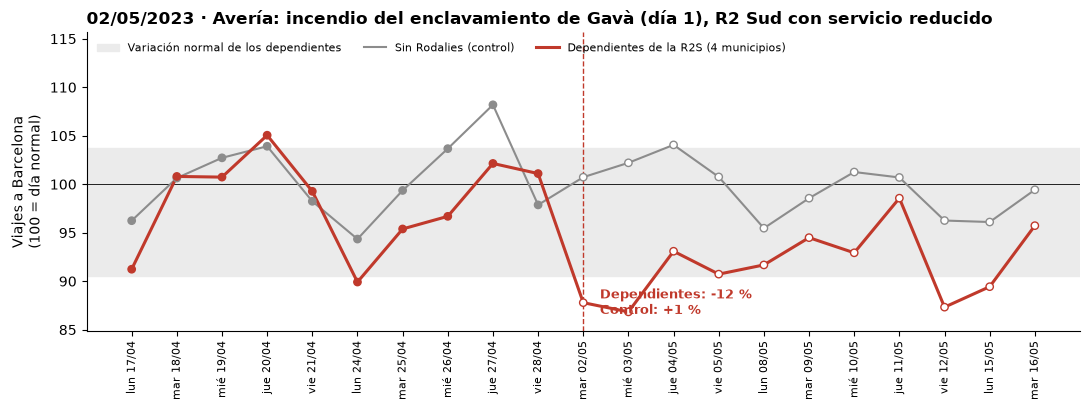

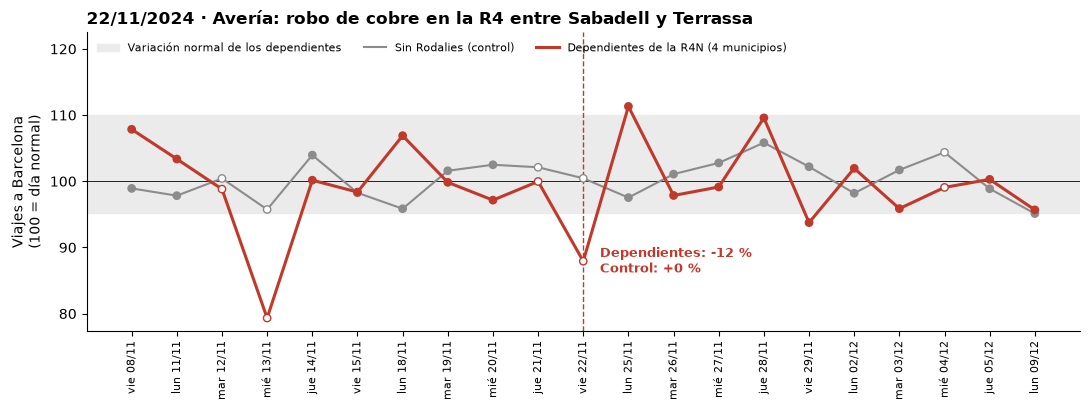

In [35]:
for fecha, (linea, desc) in AVERIAS_LINEA.items():
    DIAS_CAOS[fecha] = desc                       # solo para el título del gráfico (no cambia caos_real)
    afect = list(dep.index[dep_L.map(lambda s: linea in s)])
    grafico_dia(fecha, codes=afect, etiqueta=f"Dependientes de la {linea} ({len(afect)} municipios)")

**Resultado.**
- **02/05/2023, Gavà (R2 Sud):** los dependientes de la R2 Sud caen un **−11,6 %** (margen de error [−19,3, −0,6],
  p = 0,03), ≈ **2.900 viajes menos** de ≈ 25.000. Los de las demás líneas no cambian (−0,8 %). En el gráfico se ve que
  la caída se mantiene durante las dos semanas de servicio reducido.
- **22/11/2024, robo de cobre (R4 Nord):** **−10,3 %** (p = 0,04); las demás líneas, −2,7 %. Es el caso más débil: solo
  son 4 municipios pequeños (≈ 160 viajes menos de ≈ 1.600) y el margen de error llega a +1,2 %.
- La regresión da la misma dirección, con caídas mayores (−17 % y −18 %).
- **En el total de la línea casi no se nota.** La R2 Sud entera no cambia (−0,1 %): pesan mucho los municipios grandes
  y cercanos con metro o bus (L'Hospitalet, El Prat, Gavà, Viladecans). En la R4 Nord el total baja un −4,1 %, pero la
  R4 Sud, que debía servir de referencia, también baja (−3,0 %): esa tarde hubo además un corte en la R4 entre Cornellà
  y Molins de Rei, así que esa caída no se puede atribuir a una sola avería.

**Lectura.** Lo mismo que en los días de caos: cuando una línea se queda sin servicio normal durante muchas horas
(todo el día en Gavà), quien depende de ella deja de hacer una parte de los viajes. Una avería de dos horas por la
tarde no lo hace (sección 4.5).

*Descartada: el 08/05/2025 (rotura de una aguja en Sitges, R2 Sud, todo el día) también da ≈ −12 % en los dependientes
de la R2 Sud, pero ya estaban ≈ 10 % por debajo de lo normal las dos semanas anteriores (después del apagón), también
en días limpios. La caída no es de ese día, así que no se incluye.*

## 5. ¿Es real o casualidad?

### 5.1 La prueba del día falso

Cogemos **200 grupos de días normales al azar**, hacemos como si fueran días de caos y repetimos el cálculo.
Si el método funciona, con días normales no debería salir ninguna caída.

Efecto real: -6.2 % · días falsos: 95 % entre -2.8 % y 2.7 % · grupos falsos con una caída igual o mayor: 0 de 200 · p = 0.0002


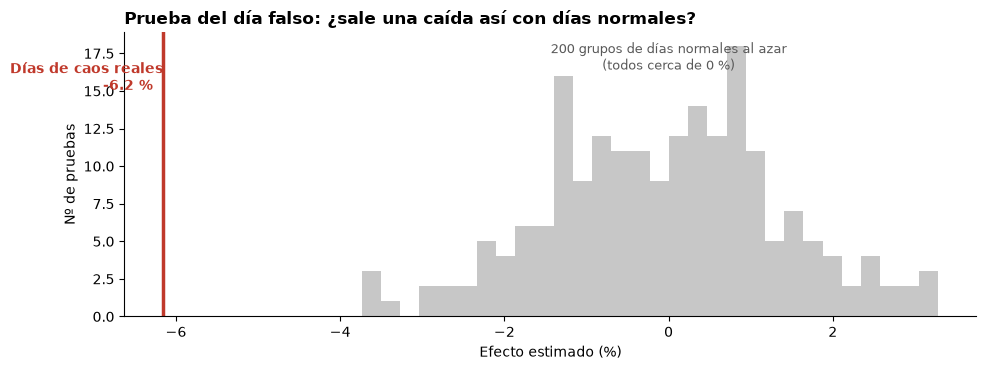

In [36]:
N_PLAC = 200
DEP_CODES = info.index[info.dependiente]

# Efecto real (media de los días de caos) y 200 grupos de días normales al azar (placebos del clustering)
real, p_plac, _, _ = metodo_clustering(DEP_CODES, caos_real)
obs = np.log(1 + real / 100)
plac_dia = placebos_clustering(DEP_CODES)
rng = np.random.default_rng(0)
plac = rng.choice(plac_dia, (N_PLAC, len(caos_real))).mean(axis=1)          # efecto (log) de cada grupo de días falsos
print(f"Efecto real: {real:.1f} % · días falsos: 95 % entre {_pct(np.percentile(plac, 2.5)):.1f} % "
      f"y {_pct(np.percentile(plac, 97.5)):.1f} % · grupos falsos con una caída igual o mayor: {np.sum(plac <= obs)} de {N_PLAC} "
      f"· p = {p_plac:.4f}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(_pct(plac), bins=30, color="0.78")
ax.axvline(real, color=ROJO, lw=2.5)
ymax = ax.get_ylim()[1]
ax.text(real, ymax * .9, f"Días de caos reales\n{real:.1f} %  ", color=ROJO, fontweight="bold", ha="right", va="top")
ax.text(0, ymax * .97, f"{N_PLAC} grupos de días normales al azar\n(todos cerca de 0 %)", ha="center", va="top",
        fontsize=9, color="0.35")
ax.set_xlabel("Efecto estimado (%)"); ax.set_ylabel("Nº de pruebas")
ax.set_title("Prueba del día falso: ¿sale una caída así con días normales?", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

# Panel para la comprobación con regresión (anexo B.4)
base = todos[todos.municipio_code.isin(info.index[info.dependiente | ~info.rodalies])
             & ~todos.fecha.isin(averias_linea)].copy()                # las averías (4.6) no cuentan como días normales
base["dependiente"] = base.municipio_code.isin(info.index[info.dependiente]).astype(int)
base["caos"] = base.fecha.isin(caos_real).astype(int)

**Resultado.** Con días normales el efecto es siempre ≈ 0 % (el 95 % de los grupos de días falsos, entre −2,8 % y +2,7 %).
La caída de los días de caos reales (**−6,2 %**) queda muy lejos: **ninguna de las 200 pruebas la alcanza** (p < 0,001).
La caída no es casualidad ni un error del método.

### 5.2 ¿Cuánto dura el efecto?

Se calcula el efecto en los dependientes no solo el día del caos, sino también los 5 días **anteriores** y los 3
**posteriores**. Como en el resto del análisis, solo cuentan los días limpios (sin lluvia, eventos ni otras incidencias);
cada uno se compara con los días de su tipo, sin incluirse a sí mismo.

- **Antes del caos** debería ser ≈ 0: si no, los dos grupos ya se comportaban distinto y la comparación no valdría.
- **Después del caos** indica si el impacto se mantiene.

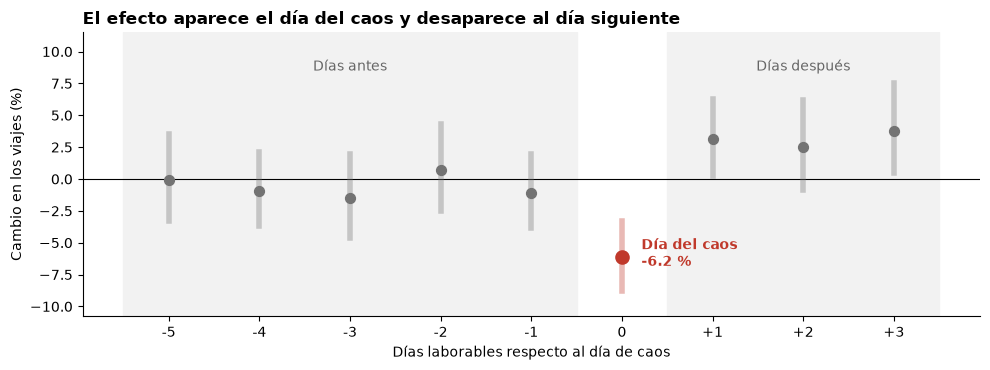

In [37]:
# ── Clustering: efecto de cada día laborable alrededor de los días de caos ──────
# Secuencia de días como en la regresión: días limpios + días de caos (sin lluvia, eventos ni otras incidencias)
LAB = V.index.difference(pd.DatetimeIndex([pd.Timestamp(CASO_CONTRASTE[0])]).union(averias_linea))
vol_all = vol_ctrl.combine_first(np.log(V_all[CTRL].sum(axis=1, min_count=len(CTRL) // 2)))
S_DEP_ALL = V_all[DEP].sum(axis=1, min_count=len(DEP) // 2)

def ref_de(f):
    """Días de referencia de f: placebo leave-one-out si f es un día limpio; si no, días limpios de su tipo."""
    if f in REF_LOO:
        return REF_LOO[f]
    _, _, tipos = modelos[f.year]
    return tipos.index[tipos == tipo_de_dia(f, vol_all)]

def evento_clustering(dias, ks=range(-5, 4), n_sim=20000, seed=0):
    """Efecto medio (dependientes, corregido por el control) k días antes/después de los días de caos (secuencia de días limpios)."""
    plac = placebos_clustering(DEP_CODES); rng = np.random.default_rng(seed); filas = []
    otros = [x for x in caos_real if x not in set(dias)]
    lab = LAB.difference(pd.DatetimeIndex(otros))             # los demás días de caos no cuentan en la secuencia
    for k in ks:
        efs = []
        for d in dias:
            i = lab.get_loc(d)
            if not 0 <= i + k < len(lab): continue
            f = lab[i + k]
            if k != 0 and f in caos_real: continue          # otro día de caos: no cuenta como día normal
            if f.year not in modelos or pd.isna(vol_all.get(f)) or pd.isna(S_DEP_ALL.get(f)): continue
            ref = ref_de(f)
            e = np.log(S_DEP_ALL[f] / S_DEP_ALL.reindex(ref).median()) - np.log(tot_ctrl[f] / tot_ctrl.reindex(ref).median())
            if np.isfinite(e): efs.append(e)
        if not efs: continue
        obs_k = np.mean(efs)
        dist = plac if len(efs) == 1 else rng.choice(plac, (n_sim, len(efs))).mean(axis=1)
        filas.append({"k": k, "dias": len(efs), "efecto_%": _pct(obs_k),
                      "lo": _pct(obs_k - np.quantile(dist, .975)), "hi": _pct(obs_k - np.quantile(dist, .025)),
                      "p": (1 + (dist <= obs_k).sum()) / (len(dist) + 1)})
    return pd.DataFrame(filas)

t = evento_clustering(sorted(caos_real))

# ── Comprobación con regresión (anexo B.4) ───────────────────────────────────
fechas_panel = np.sort(base.fecha.unique()); pos = {f: i for i, f in enumerate(fechas_panel)}
rel = pd.Series("fuera", index=pd.DatetimeIndex(fechas_panel))
for d in sorted(caos_real):
    i0 = pos[np.datetime64(d)]
    for k in range(-5, 4):
        j = i0 + k
        if 0 <= j < len(fechas_panel):
            f = fechas_panel[j]
            if rel[f] == "fuera" or abs(k) < abs(int(rel[f])): rel[f] = str(k)
es = base.copy()
es["rel_dep"] = np.where(es.dependiente == 1, es.fecha.map(rel), "fuera")
t_reg = pf.feols("y ~ i(rel_dep, ref='fuera') | mun_dow + fecha", data=es, vcov={"CRV1": "municipio_code"}).tidy()
t_reg["k"] = [int(i.split("::")[-1]) for i in t_reg.index]; t_reg = t_reg.sort_values("k")
t_reg["efecto_%"] = (np.exp(t_reg.Estimate) - 1) * 100
t_reg["lo"] = (np.exp(t_reg["2.5%"]) - 1) * 100; t_reg["hi"] = (np.exp(t_reg["97.5%"]) - 1) * 100


fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axvspan(-5.5, -0.5, color="0.95"); ax.axvspan(0.5, 3.5, color="0.95")
ax.text(-3, t.hi.max() + 1, "Días antes", ha="center", color="0.4")
ax.text(2, t.hi.max() + 1, "Días después", ha="center", color="0.4")
ax.axhline(0, color="black", lw=.8)
for _, r in t.iterrows():
    c = ROJO if r.k == 0 else "0.45"
    ax.plot([r.k, r.k], [r.lo, r.hi], color=c, lw=4, alpha=.35)
    ax.scatter(r.k, r["efecto_%"], color=c, s=90 if r.k == 0 else 50, zorder=3)
ax.annotate(f"Día del caos\n{t.loc[t.k == 0, 'efecto_%'].iloc[0]:+.1f} %", (0, t.loc[t.k == 0, "efecto_%"].iloc[0]),
            xytext=(14, -6), textcoords="offset points", color=ROJO, fontweight="bold")
ax.set_xticks(range(-5, 4), [f"{k:+d}" if k else "0" for k in range(-5, 4)])
ax.set_xlabel("Días laborables respecto al día de caos"); ax.set_ylabel("Cambio en los viajes (%)")
ax.set_ylim(t.lo.min() - 2, t.hi.max() + 4)
ax.set_title("El efecto aparece el día del caos y desaparece al día siguiente", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Resultado.** Los días anteriores al caos el efecto es ≈ 0 (entre −1,5 % y +0,7 %, ninguno claro): los dos grupos se
comportaban igual, así que la comparación es válida. El día del caos los viajes caen un **−6,2 %** y **al día siguiente
vuelven a la normalidad**. El impacto dura un solo día. Los días posteriores salen incluso algo por encima (≈ +3 %),
lo que podría ser la recuperación de viajes aplazados; la regresión no lo confirma (anexo B.4), así que no se interpreta.

---
## 6. Conclusiones

1. **Las incidencias graves de Rodalies reducen los viajes a Barcelona solo donde el tren no tiene
   alternativa.** En los días de caos con un efecto claro, los municipios dependientes (≥ 20 km y sin metro ni FGC)
   pierden entre un 7 % y un 10 % de sus viajes (−6,2 % de media en los 4 días; ≈ 4.400 viajes menos por día).
   Los municipios con metro/FGC no cambian y los cercanos caen un poco (≈ −2 %).
2. **Cuanto más lejos, más impacto** (≈ 0 % a < 15 km; −5,4 % entre 15 y 30 km; −7,3 % a > 30 km).
3. **Cada línea reacciona distinto.** En una avería cae la línea cortada (13/05/2024: Maresme, R1, −14 %; Osona, R3, −28 %).
   En la huelga del 17/03/2025 caen casi todos los corredores; en las huelgas anunciadas el efecto es menor y desigual,
   y el Garraf (R2 Sud) es el más afectado el 01/04 (−15 %).
4. **No basta con que haya muchos viajeros afectados.** La avería del 05/06/2025, la mayor del registro
   oficial entre los días analizables, duró menos de dos horas por la tarde y no redujo los viajes (sección 4.5).
   Lo que hace caer la movilidad es quedarse sin tren para ir.
5. **Una avería de una sola línea también cuenta si deja la línea sin servicio normal durante horas:** el primer día
   del incendio de Gavà (02/05/2023) los dependientes de la R2 Sud caen un −12 %, y con el robo de cobre del 22/11/2024,
   los de la R4 Nord un −10 % (caso más débil, con solo 4 municipios). Las demás líneas no cambian (sección 4.6).
6. **El impacto de los días de caos dura un día:** desaparece al día siguiente.
7. **Es un efecto real:** la prueba del día falso nunca da una caída así, y la regresión (anexo B) llega a la
   misma conclusión.

**Interpretación.** La gran mayoría de la gente mantiene el viaje ante una incidencia, cambiando de línea,
de medio o de ruta. Solo donde no hay alternativa desaparece una parte de los viajes (teletrabajo, aplazamiento).

**Limitaciones.**
- Los datos no identifican el medio de transporte y son diarios (no por horas).
- Hay pocos días de caos válidos (4) y algunas líneas tienen pocos municipios (R3, R2 Nord): sus márgenes de error
  son amplios, y algún resultado por línea depende del método (R2 Sud).
- El registro oficial de incidencias solo recoge las de Rodalies con más de 10.000 viajeros afectados (y solo el primer
  día de cada una; los cortes largos se excluyen enteros): los días limpios pueden contener incidencias menores.
- Los municipios de control pueden notar el caos de forma indirecta (tráfico): el efecto real podría ser algo mayor.
- Las averías de una sola línea solo se pueden medir en pocos municipios dependientes (4 en la R2 Sud y en la R4 Nord):
  sus márgenes de error son muy amplios. De 18 averías importantes probadas, solo estas dos tienen una caída clara
  atribuible a ese día.
- Los municipios muy pequeños quedan fuera (ceros por privacidad).
- Los viajes perdidos son una estimación aproximada (efecto medio × volumen normal del grupo).

**Trabajo futuro.**
- **M3 (barrios de destino, notebook 05):** la caída se concentra en los barrios con estación de Rodalies.
- Datos horarios, validaciones de billetes (T-mobilitat) y aforos de tráfico.

---
# B. Anexo técnico

Detalle de los métodos, tablas completas con los dos métodos y exportaciones.

### B.1 Método principal: clustering + mediana (corregido por el control)

*Es el método del que salen todas las cifras de los resultados.*

**Idea.** El clustering clasifica los días; no mide la incidencia. Para cada año, los días limpios se
agrupan con K-means en **4 tipos (A–D)** según dos variables: el log de los viajes a Barcelona de los
**municipios sin Rodalies** (a los que ninguna incidencia de Rodalies afecta) y la **época del año**.
En la práctica, cada año se separa en dos épocas (enero–junio y septiembre–diciembre) y, dentro de
cada una, en días de volumen alto y bajo.

**Cómo se compara un día de incidencia:**
1. Se clasifica el día en un tipo según los municipios sin Rodalies y su fecha (no según los afectados,
   para evitar circularidad: si no, un día con menos viajes por la incidencia parecería un «día flojo»).
2. Se calcula la mediana de viajes del grupo afectado en los días limpios de ese tipo («lo normal»).
3. Efecto = (viajes del grupo / su mediana) ÷ (viajes de los municipios sin Rodalies / su mediana) − 1.
   Así se descuenta lo que le pasó a todo el mundo ese día.
4. Significación y margen de error a partir de los placebos (ver B.3).

**Cómo se eligió esta versión** (notebook `04.2_clustering_experimentos`). Se probaron varias variantes
con una regla fijada de antemano: tratar cada día limpio como un falso día de caos (efecto real = 0) y
quedarse con la variante de menor error, sin mirar los días de caos. Respecto a la versión anterior
(K-means con k = 3 solo sobre el volumen y sin corregir por el control):
- El error típico en los dependientes baja del 3,45 % al 3,0 %, y la mejora es significativa (bootstrap por meses).
- El intervalo de los placebos pasa de [−7,3 %, +5,8 %] a [−6,1 %, +5,3 %].
- Desaparece la ligera caída que antes salía en todos los grupos.
- La correlación con la regresión en los días de caos sube de 0,62 a 0,75.

La mejora viene de la **estacionalidad**: el cociente dependientes/control es más alto de enero a marzo
y más bajo de octubre a diciembre, y agrupar solo por volumen mezclaba esas épocas. Añadir el día de la
semana no ayuda, y GMM o el clustering jerárquico de Ward no mejoran a K-means. Los tipos son
estables (ARI medio de 0,76–0,85 en bootstrap), aunque los días de la frontera entre tipos pueden
cambiar de grupo.

### B.2 Comprobación: regresión (diferencias en diferencias)

*Se usa para comprobar que el resultado no depende del método (B.6).*

**Idea.** Se comparan, **el mismo día**, los municipios afectados con los municipios sin Rodalies.

Ejemplo: si un día de caos Vic tiene un 10 % menos de viajes de lo normal e Igualada (sin Rodalies)
un 2 % menos, ese 2 % es «lo que pasó a todo el mundo» y el efecto del tren es −10 % − (−2 %) = −8 %.

**Modelo:** 

$$
\log(\text{viajes}_{m,t}) = \alpha_{m,\,d(t)} + \delta_t + \beta \cdot \text{tratado}_{m,t} + \varepsilon_{m,t}
$$

donde:
- $\text{viajes}_{m,t}$: viajes a Barcelona desde el municipio $m$ el día $t$.
- $\alpha_{m,\,d(t)}$: efecto fijo de municipio × día de la semana (el volumen normal de cada municipio cada día de la semana).
- $\delta_t$: efecto fijo de fecha (lo que le pasa a todos los municipios ese día: estacionalidad, eventos, tiempo…).
- $\text{tratado}_{m,t} = 1$ si el municipio $m$ pertenece al grupo analizado y $t$ es un día de caos; 0 en otro caso.
- $\beta$: **efecto de la incidencia**. El cambio porcentual en los viajes es $(e^{\beta} - 1) \times 100$.
- $\varepsilon_{m,t}$: error, con errores estándar agrupados por municipio.

El control son los municipios sin Rodalies ($\text{tratado} = 0$ siempre).

**Funciones comunes:** `comparar()` aplica los dos métodos al mismo grupo de municipios y los mismos días.

### B.3 ¿Cómo se decide si un efecto es significativo?

Los viajes de cada municipio varían de un día a otro sin motivo especial (ruido). Para saber si
una caída se debe a la incidencia o al azar se usa el **p-valor**: la probabilidad de observar
un efecto igual o mayor si la incidencia no tuviera ningún efecto.

- **p < 0,05 → efecto significativo:** menos de un 5 % de probabilidad de que sea casualidad.
- **p ≥ 0,05 → no significativo:** no se puede descartar que sea ruido (no implica que no haya efecto).

**Clustering (cifra principal):** el p-valor es la proporción de **placebos** con un efecto igual o más
bajo que el del día de incidencia. Los placebos son los días limpios tratados como falsos días de caos, con el
clustering reentrenado sin ese día (≈ 260 días). Por ejemplo, p = 0,004 indica que solo 1 de cada 250 días
normales da una caída tan grande. El **margen de error del 95 %** es el efecto observado menos los percentiles
97,5 y 2,5 de los placebos. Con varios días de caos, se compara la media de sus efectos con la media de los mismos
placebos tomados al azar. Municipio a municipio, el p-valor es bilateral (caída o subida).

**Regresión (comprobación):** el p-valor y el intervalo de confianza del 95 % se calculan a partir de la
variación normal entre municipios y días (errores agrupados por municipio).

**Cautelas:** significativo no implica que el efecto sea grande, y no significativo no implica que
no exista. Como se hacen varias pruebas, se da más peso a los resultados que se repiten (grupos,
distancia, días distintos y los dos métodos) que a un resultado aislado.

### B.4 ¿Cuánto dura el efecto? (sección 5.2)

**Clustering (cifra principal).** Se toma la secuencia de días limpios + días de caos (la misma que usa la regresión) y,
para cada día de caos, el día que está k posiciones antes o después (k = −5…3). Los demás días de caos no cuentan. El
efecto de cada día se calcula igual que el del día de caos: frente a los días de su tipo, sin incluirse a sí mismo, y
corregido por el control. Se promedian los 4 días de caos y el margen de error sale de los placebos.

**Regresión (comprobación):**

$$
\log(\text{viajes}_{m,t}) = \alpha_{m,\,\text{dow}} + \delta_t + \sum_{k=-5}^{3} \beta_k \cdot \mathbb{1}[\text{dependiente}_m]\cdot\mathbb{1}[t = \text{caos} + k] + \varepsilon_{m,t}
$$

En los dos métodos, los efectos previos (k < 0) comprueban el supuesto de **tendencias paralelas**.

In [38]:
print("Clustering (cifra principal)")
display(t.set_index("k")[["dias", "efecto_%", "lo", "hi", "p"]].round(3))
print("Regresión (comprobación)")
display(t_reg.set_index("k")[["efecto_%", "lo", "hi", "Pr(>|t|)"]].round(2))

Clustering (cifra principal)


,dias,efecto_%,lo,hi,p
k,,,,,
-5,3,-0.059,-3.267,3.548,0.452
-4,4,-0.936,-3.688,2.140,0.244
-3,3,-1.482,-4.617,1.996,0.170
-2,3,0.742,-2.480,4.349,0.652
-1,4,-1.084,-3.836,1.980,0.210
0,4,-6.158,-8.788,-3.274,0.000
1,4,3.127,0.257,6.258,0.984
2,3,2.479,-0.855,6.180,0.923
3,3,3.731,0.439,7.508,0.987


Regresión (comprobación)


,efecto_%,lo,hi,Pr(>|t|)
k,,,,
-5,-1.67,-5.13,1.92,0.35
-4,0.37,-2.64,3.47,0.81
-3,-2.99,-7.15,1.36,0.17
-2,-1.19,-4.86,2.62,0.53
-1,-2.77,-6.34,0.93,0.14
0,-6.81,-10.29,-3.21,0.00
1,0.35,-3.09,3.92,0.84
2,1.93,-1.90,5.92,0.32
3,-0.84,-5.06,3.56,0.70


### B.5 Tablas completas con los dos métodos

In [39]:
print("Por grupo de municipios"); display(res_grupos)
print("Por distancia");           display(res_dist)
print("Por línea y día (clustering)")
display(res_lineas.assign(fecha=res_lineas.fecha.dt.strftime("%d/%m/%Y"))
        .round({"cambio_%": 1, "lo": 1, "hi": 1, "p": 3, "viajes_dia_normal": -1, "viajes_perdidos": -1}))

Por grupo de municipios


,municipios,cambio_%,IC95,p,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,,,,
"Dependientes (≥20 km, sin metro/FGC)",35,-6.2,"[-8.8, -3.3]",0.000,-6.2,0.000,-6.8,"[-10.2, -3.3]",0.000
Cercanos sin metro/FGC (<20 km),16,-2.2,"[-4.8, -0.1]",0.018,-2.2,0.018,-2.7,"[-6.2, 0.9]",0.140
Con metro/FGC,11,-1.0,"[-3.2, 0.4]",0.071,-1.0,0.071,1.7,"[-1.1, 4.5]",0.245


Por distancia


,municipios,cambio_%,IC95,p,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,,,,
Sin metro/FGC · < 15 km,8,0.2,"[-3.4, 3.2]",0.507,0.2,0.507,-1.5,"[-5.6, 2.8]",0.494
Sin metro/FGC · 15–30 km,16,-5.4,"[-7.6, -3.1]",0.000,-5.4,0.000,-3.3,"[-7.1, 0.7]",0.100
Sin metro/FGC · > 30 km,27,-7.3,"[-11.3, -3.9]",0.000,-7.3,0.000,-8.0,"[-11.6, -4.2]",0.000


Por línea y día (clustering)


,fecha,linea,municipios,cambio_%,lo,hi,p,viajes_dia_normal,viajes_perdidos,claro
0,13/05/2024,R1,12,-13.5,-18.7,-5.3,0.011,24140.0,3260.0,True
1,13/05/2024,R2N,4,5.9,-3.1,20.3,0.875,4870.0,-290.0,False
2,13/05/2024,R2N+R3,2,-5.3,-12.2,3.2,0.121,8920.0,470.0,False
3,13/05/2024,R2S,4,-8.6,-16.6,2.8,0.055,23100.0,1990.0,False
4,13/05/2024,R3,5,-28.2,-50.0,-5.5,0.026,6820.0,1920.0,True
5,13/05/2024,R4,8,-5.2,-19.5,8.1,0.183,5690.0,300.0,False
6,17/03/2025,R1,12,-7.7,-13.2,1.1,0.040,24070.0,1850.0,True
7,17/03/2025,R2N,4,-11.2,-18.7,0.9,0.044,5280.0,590.0,True
8,17/03/2025,R2N+R3,2,-11.4,-17.8,-3.5,0.007,9350.0,1070.0,True
9,17/03/2025,R2S,4,-8.9,-16.8,2.5,0.055,21930.0,1950.0,False


### B.6 Comparación de los dos métodos

,municipios,cambio_%,IC95,p,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
grupo,,,,,,,,,
Días de caos (media) · dependientes,35,-6.2,"[-8.8, -3.3]",0.000,-6.2,0.000,-6.8,"[-10.2, -3.3]",0.000
17/03/2025 huelga · dependientes,35,-8.9,"[-13.3, -3.0]",0.011,-8.9,0.011,-10.7,"[-15.5, -5.6]",0.000
13/05/2024 avería · dependientes,35,-10.3,"[-14.7, -4.6]",0.007,-10.3,0.007,-8.5,"[-13.7, -3.1]",0.003
13/05/2024 avería · dependientes R1,12,-13.5,"[-18.7, -5.3]",0.011,-13.5,0.011,-17.2,"[-23.5, -10.4]",0.000


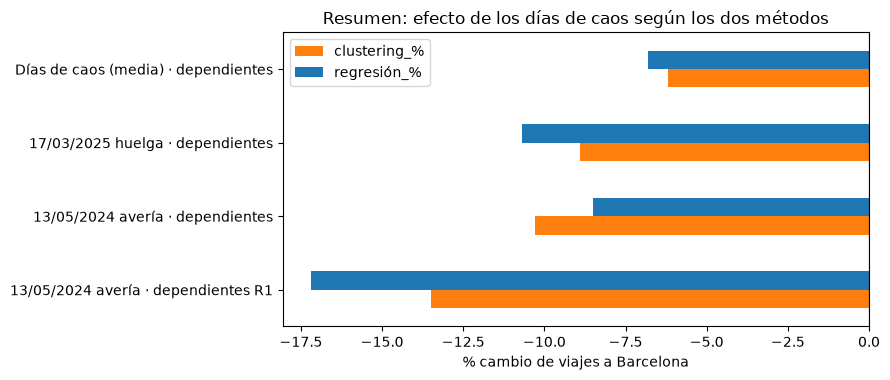

In [40]:
casos = {"Días de caos (media) · dependientes": (info.index[info.dependiente], caos_real),
         "17/03/2025 huelga · dependientes": (info.index[info.dependiente], [pd.Timestamp("2025-03-17")]),
         "13/05/2024 avería · dependientes": (info.index[info.dependiente], [pd.Timestamp("2024-05-13")]),
         "13/05/2024 avería · dependientes R1": (dep.index[dep.lineas == "R1"], [pd.Timestamp("2024-05-13")])}
filas = []
for nombre, (codes, dias) in casos.items():
    dias = [d for d in dias if d in caos_real]
    if dias: filas.append(comparar({nombre: codes}, dias))
resumen_final = pd.concat(filas)
display(resumen_final); resumen_final.to_csv(OUT / "resumen_final_metodos.csv")
grafico_barras(resumen_final, "Resumen: efecto de los días de caos según los dos métodos")

**Resultado.** Los dos métodos coinciden en dirección, magnitud y significación en los dependientes:

| Caso | Clustering | Regresión |
|---|---|---|
| Días de caos (media) · dependientes | −6,2 % | −6,8 % |
| 17/03/2025, huelga · dependientes | −8,9 % | −10,7 % |
| 13/05/2024, avería · dependientes | −10,3 % | −8,5 % |
| 13/05/2024, avería · dependientes R1 | −13,5 % | −17,2 % |

Las pequeñas diferencias se deben a que el clustering suma volúmenes (da más peso a los municipios
grandes) y compara con los días normales de la misma época, mientras que la regresión pondera igual
cada municipio y usa todos los días limpios del periodo. Donde más difieren es en los resultados por línea
con pocos municipios (por ejemplo, la R2 Sud en las huelgas: ver sección 4.3).

### B.7 Exportación para el análisis de M3

Se guardan los objetos necesarios para analizar M3 con exactamente los mismos criterios: el calendario
de días limpios (`cal`), los días de caos (`caos_real`), la clasificación de municipios (`info`), el
volumen de control (`vol_ctrl`) y el tipo de día asignado por el clustering (`tipos_dia`).
Las averías de una línea (4.6) se guardan aparte (`m2_averias_linea.parquet`) para que M3 y el dashboard
sigan usando solo los días de caos.

In [41]:
cal.to_parquet(OUT / "m2_cal.parquet")
info.to_parquet(OUT / "m2_info_municipios.parquet")
vol_ctrl.to_frame("vol_ctrl").to_parquet(OUT / "m2_vol_ctrl.parquet")
pd.Series(sorted(caos_real), name="fecha").to_frame().to_parquet(OUT / "m2_caos_real.parquet")
pd.DataFrame([{"fecha": pd.Timestamp(f), "linea": l, "descripcion": t} for f, (l, t) in AVERIAS_LINEA.items()]
             ).to_parquet(OUT / "m2_averias_linea.parquet")

In [42]:
# Tipo de día para TODOS los días con datos (no solo los limpios y de caos), para que M3 no tenga que recalcularlo
vol_ctrl_all = np.log(V_all[CTRL].sum(axis=1, min_count=len(CTRL) // 2)).dropna()
vol_tipos = vol_ctrl.combine_first(vol_ctrl_all)          # en los días limpios y de caos, exactamente el de M2
partes = []
for y, (pipe, nombre, _) in modelos.items():
    dd = vol_tipos.dropna().index[vol_tipos.dropna().index.year == y]
    partes.append(pd.Series([nombre[c] for c in pipe.predict(variables_dia(dd, vol_tipos))], index=dd))
tipos_dia = pd.concat(partes).rename("tipo")

# Comprobación: en los días limpios, el tipo exportado coincide con el del clustering
lim_ok = pd.concat([m[2] for m in modelos.values()])
print(len(tipos_dia), "días con tipo asignado · coincidencia en días limpios:",
      f"{(tipos_dia.reindex(lim_ok.index) == lim_ok).mean():.0%}")
tipos_dia.astype(str).to_frame().to_parquet(OUT / "m2_tipos_dia.parquet")

971 días con tipo asignado · coincidencia en días limpios: 100%


### B.8 Exportación para el Observatorio (dashboard)
Junta en un JSON todos los resultados de este notebook (clustering): para cada día de caos, el efecto por grupo, los viajes
perdidos, la serie diaria, el volumen por tramo (4.1), las líneas, el mapa por municipio y la duración; y, en conjunto, grupos,
distancia, efecto según la alternativa en transporte público, placebo y event study; y las averías de una línea
(sección 4.6): `data/processed/rmove/resultados/dashboard_resultados.json`. Los resultados por barrio (M3) los exporta el
notebook 05 (`m3_resultados.json`).

Se ejecuta **al final del notebook**, con todas las celdas anteriores ya ejecutadas. Para actualizar todo el dashboard
(notebooks 04, 05 y socioeco y el JSON del Observatorio), desde la raíz del repositorio: `python scripts/actualizar_dashboard.py`.

In [43]:
# ── Exportación para el dashboard: pestañas «Incidencias» y «Resultados» ─────
# Ejecutar AL FINAL del notebook (usa los objetos de las secciones 1–5 y del anexo B).
import hashlib, json, math

def exportar_resultados(destino=None):
    destino = destino or (PROC / "rmove" / "resultados" / "dashboard_resultados.json")

    def num(x, d=2):
        x = float(x); assert math.isfinite(x), "Valor no finito"; return round(x, d)
    def efecto(f):          # fila de comparar() → efecto, IC y p del clustering
        lo, hi = map(float, f["IC95"].strip("[]").split(","))
        return {"efecto_pct": num(f["cambio_%"]), "ic_inf": num(lo), "ic_sup": num(hi), "p_valor": num(f["p"], 4)}

    NOMBRES_LINEA = {"R1": "R1", "R2N": "R2 Nord", "R2S": "R2 Sud", "R3": "R3", "R4": "R4", "R7": "R7"}
    TODAS = ["R1", "R2 Nord", "R2 Sud", "R3", "R4", "R7"]
    FICHAS = {
        "2024-05-13": {"titulo": "Robo de cobre en Montcada", "tipo": "Avería",
                       "descripcion": "Primer día laborable tras el robo de cable en Montcada Bifurcació (domingo 12/05). Avería sin aviso previo.",
                       "tramo": "R1 solo entre Badalona y Arenys · R3 solo hasta Montcada Ripollet · R4 Nord hasta Cerdanyola y R4 Sud hasta L'Hospitalet · R7 sin servicio",
                       "lineas": ["R1", "R2 Nord", "R3", "R4", "R7"],
                       "lectura": "Caída concentrada en la línea cortada: el Maresme (R1), sobre todo al norte de Arenys, donde no había tren. Osona (R3), que solo llegaba hasta Montcada, también cae."},
        "2025-03-17": {"titulo": "Huelga de Rodalies", "tipo": "Huelga",
                       "descripcion": "Huelga de los sindicatos minoritarios contra el traspaso de Rodalies: retrasos y supresiones en toda la red.",
                       "tramo": "Toda la red", "lineas": TODAS,
                       "lectura": "Caos generalizado: caen los corredores más alejados, Osona (R3), el Vallès Oriental (R2 Nord), Granollers y el Maresme (R1)."},
        "2025-03-26": {"titulo": "Huelga de 24 horas", "tipo": "Huelga",
                       "descripcion": "Jornada de huelga anunciada en Rodalies.",
                       "tramo": "Toda la red", "lineas": TODAS,
                       "lectura": "Huelga anunciada: el total no cambia y ninguna línea cae de forma clara; los viajes se redistribuyen hacia barrios sin estación (M3)."},
        "2025-04-01": {"titulo": "Huelga de 24 horas", "tipo": "Huelga",
                       "descripcion": "Jornada de huelga anunciada en Rodalies. Coincide con averías de electrificación en la R4 (Castellbisbal) y la R2 Nord (vía única La Llagosta–Sant Andreu) desde el 31/03.",
                       "tramo": "Toda la red", "lineas": TODAS,
                       "lectura": "Huelga anunciada: el Garraf (R2 Sud) es el corredor más afectado."},
    }
    grupo_json = {"Dependiente": "dependientes", "Cercano sin metro/FGC": "cercanos",
                  "Con metro/FGC": "metro_fgc", "Sin Rodalies (control)": "sin_rodalies"}
    grupos_reg = {"dependientes": info.index[info.dependiente],
                  "cercanos": info.index[info.grupo == "Cercano sin metro/FGC"],
                  "metro_fgc": info.index[info.con_alt]}
    limpios = todos[todos.fecha.isin(cal.index[cal.limpio])]
    viajes_ref = limpios.groupby("municipio_code").viajes.median()

    incidencias = []
    for d in sorted(caos_real):
        fecha = d.strftime("%Y-%m-%d"); ficha = FICHAS.get(fecha, {"titulo": DIAS_CAOS[fecha], "tipo": "", "descripcion": "",
                                                                    "tramo": "", "lineas": [], "lectura": ""})
        # 1) Efecto por grupo (clustering, con IC)
        tabla = comparar(grupos_reg, [d])
        grupos = [{"grupo": g, "municipios": int(f.municipios), **efecto(f)} for g, f in tabla.iterrows()]
        dep_ef = next(g for g in grupos if g["grupo"] == "dependientes")
        normal = viajes_normales(DEP, d)

        # 2) Serie: dependientes vs control alrededor del día (100 = día normal)
        lab = cal.index[~(cal.finde | cal.festivo)]
        i = lab.get_loc(d); fechas = lab[max(0, i - 10): i + 11]
        ref = fechas[cal.loc[fechas, "limpio"].values]
        if len(ref) < 5: ref = cal.index[cal.limpio & (cal.index.year == d.year)]
        idx_dep = tot_dep.reindex(fechas) / tot_dep.reindex(ref).median() * 100
        idx_ctrl = tot_ctrl.reindex(fechas) / tot_ctrl.reindex(ref).median() * 100
        lo, hi = idx_dep.reindex(ref).quantile([.05, .95])
        serie = [{"fecha": f.strftime("%Y-%m-%d"), "dependientes": num(idx_dep[f]), "control": num(idx_ctrl[f]),
                  "limpio": bool(cal.at[f, "limpio"]), "caos": bool(f in caos_real)}
                 for f in fechas if math.isfinite(idx_dep[f]) and math.isfinite(idx_ctrl[f])]

        # 3) Volumen total por tramo de línea (sección 4.1)
        tramos = []
        for etiqueta, linea, selector, afectada in TRAMOS.get(fecha, []):
            codes = municipios_tramo(linea, selector)
            if not codes: continue
            r = efecto_volumen(codes, d)
            tramos.append({"tramo": etiqueta, "linea": NOMBRES_LINEA.get(linea.split()[0], linea) + (" " + linea.split()[1] if " " in linea else ""),
                           "afectada": bool(afectada), "municipios": len(codes),
                           "viajes_esperados": num(r["viajes_esperados"], 0), "viajes_perdidos": num(r["viajes_perdidos"], 0),
                           "cambio_pct": num(r["cambio_%"]), "normal_inf": num(r["normal_lo"]), "normal_sup": num(r["normal_hi"]),
                           "p_valor": num(r["p"], 4), "lista": ", ".join(lm.loc[codes, "municipio"])})

        # 4) Dependientes por línea (sección 4.2)
        lineas_dep = [{"linea": f.linea, "municipios": int(f.municipios), "efecto_pct": num(f["cambio_%"]),
                       "ic_inf": num(f.lo), "ic_sup": num(f.hi), "p_valor": num(f.p, 4),
                       "viajes_perdidos": num(f.viajes_perdidos, 0)}
                      for _, f in res_lineas[res_lineas.fecha == d].iterrows()]

        # 5) Municipio a municipio
        r = efectos_municipio(d)
        municipios = [{"codigo": c, "nombre": f.municipio, "grupo": grupo_json[f.grupo], "lineas": f.lineas,
                       "dist_km": num(f.dist_km, 1), "lat": num(f.stop_lat, 5), "lon": num(f.stop_lon, 5),
                       "viajes_referencia": num(viajes_ref.get(c, f.viajes_dia), 0),
                       "efecto_pct": num(f["efecto_%"]), "p_valor": num(f.p, 4)}
                      for c, f in r.sort_index().iterrows()]

        # 6) Duración en esta incidencia (clustering, días laborables alrededor)
        evento = [{"dia": int(f.k), "efecto_pct": num(f["efecto_%"]), "ic_inf": num(f.lo), "ic_sup": num(f.hi)}
                  for _, f in evento_clustering([d]).iterrows() if np.isfinite(f["efecto_%"])]

        incidencias.append({
            "fecha": fecha, **ficha, "grupos": grupos,
            "perdidos": {"viajes_dia_normal": num(normal, 0), "viajes_perdidos": num(-normal * dep_ef["efecto_pct"] / 100, 0),
                         "efecto_pct": dep_ef["efecto_pct"], "p_valor": dep_ef["p_valor"]},
            "serie": serie, "banda_normal": {"inf": num(lo), "sup": num(hi)},
            "tramos": tramos, "lineas_dependientes": lineas_dep, "municipios": municipios, "evento": evento,
            "caso_od": fecha in ("2025-03-17",)})
        print(f"{fecha}: {len(municipios)} municipios, {len(tramos)} tramos, {len(lineas_dep)} líneas")

    # Averías de una sola línea (sección 4.6): misma estructura que las incidencias, medidas en la línea afectada
    NOMBRE_AV = {"R2S": "R2 Sud", "R4N": "R4 Nord", "R2N": "R2 Nord", "R4S": "R4 Sud", "R1": "R1", "R3": "R3"}
    VIAS_AV = {"R2S": ["R2 Sud"], "R4N": ["R4"], "R2N": ["R2 Nord"], "R4S": ["R4"], "R1": ["R1"], "R3": ["R3"]}
    FICHAS_AV = {
        "2023-05-02": {"titulo": "Incendio en el enclavamiento de Gavà",
                       "descripcion": "Incendio en un cuarto de señales de Gavà la noche del 01/05 (festivo). El 02/05, primer día laborable, la R2 Sud circula con servicio muy reducido; el corte dura hasta el 19/05.",
                       "tramo": "R2 Sud con servicio reducido entre El Prat y Castelldefels",
                       "lectura": "Solo cae la línea cortada: el Garraf (R2 Sud). Los dependientes de las demás líneas no cambian, y la caída se mantiene durante las dos semanas de servicio reducido."},
        "2024-11-22": {"titulo": "Robo de cobre en la R4 Nord",
                       "descripcion": "Robo de cable de cobre entre Sabadell y Terrassa, con retrasos desde el inicio del servicio. Por la tarde hubo además un corte de la R4 entre Cornellà y Molins de Rei.",
                       "tramo": "R4 Nord (Sabadell–Terrassa); por la tarde, también la R4 Sud",
                       "lectura": "Caen los dependientes de la R4 Nord y no los de las demás líneas. Es el caso más débil: solo son 4 municipios pequeños y el margen de error es amplio."},
    }
    averias = []
    for _, a in res_averias.iterrows():
        d, fecha_av, lin = a.fecha, a.fecha.strftime("%Y-%m-%d"), a.linea
        afect = list(dep.index[dep_L.map(lambda s: lin in s)])
        resto = list(dep.index[dep_L.map(lambda s: lin not in s)])
        etq = {"linea_afectada": f"Dependientes de la {NOMBRE_AV.get(lin, lin)}", "resto": "Dependientes de las demás líneas",
               "cercanos": "Cercanos sin metro/FGC", "metro_fgc": "Con metro/FGC"}
        tabla = comparar({"linea_afectada": afect, "resto": resto, "cercanos": grupos_reg["cercanos"],
                          "metro_fgc": grupos_reg["metro_fgc"]}, [d])
        grupos = [{"grupo": g, "etiqueta": etq[g], "municipios": int(f.municipios), **efecto(f)} for g, f in tabla.iterrows()]
        ga = grupos[0]
        normal = viajes_normales(afect, d)

        # Serie: dependientes de la línea afectada vs control (100 = día normal)
        s_lin = V_all[[c for c in afect if c in V_all.columns]].sum(axis=1, min_count=1)
        lab = cal.index[~(cal.finde | cal.festivo)]
        k = lab.get_loc(d); fechas = lab[max(0, k - 10): k + 11]
        ref = fechas[cal.loc[fechas, "limpio"].values]
        if len(ref) < 5: ref = cal.index[cal.limpio & (cal.index.year == d.year)]
        idx_l = s_lin.reindex(fechas) / s_lin.reindex(ref).median() * 100
        idx_c = tot_ctrl.reindex(fechas) / tot_ctrl.reindex(ref).median() * 100
        lo, hi = idx_l.reindex(ref).quantile([.05, .95])
        serie = [{"fecha": f.strftime("%Y-%m-%d"), "dependientes": num(idx_l[f]), "control": num(idx_c[f]),
                  "limpio": bool(cal.at[f, "limpio"]), "caos": bool(f == d)}
                 for f in fechas if math.isfinite(idx_l[f]) and math.isfinite(idx_c[f])]

        # Volumen total por tramo (como 4.1) y dependientes por línea ese día
        tramos = []
        for etiqueta, linea, selector, afectada in TRAMOS.get(fecha_av, []):
            codes = municipios_tramo(linea, selector)
            if not codes: continue
            r = efecto_volumen(codes, d)
            tramos.append({"tramo": etiqueta, "linea": linea, "afectada": bool(afectada), "municipios": len(codes),
                           "viajes_esperados": num(r["viajes_esperados"], 0), "viajes_perdidos": num(r["viajes_perdidos"], 0),
                           "cambio_pct": num(r["cambio_%"]), "normal_inf": num(r["normal_lo"]), "normal_sup": num(r["normal_hi"]),
                           "p_valor": num(r["p"], 4), "lista": ", ".join(lm.loc[codes, "municipio"])})
        t_lin = ic(comparar({l: dep.index[dep.lineas == l] for l in sorted(dep.lineas.unique())}, [d]))
        lineas_dep_av = [{"linea": l, "municipios": int(f.municipios), "efecto_pct": num(f["cambio_%"]),
                          "ic_inf": num(f.lo), "ic_sup": num(f.hi), "p_valor": num(f["p"], 4),
                          "viajes_perdidos": num(-viajes_normales(dep.index[dep.lineas == l], d) * f["cambio_%"] / 100, 0)}
                         for l, f in t_lin.iterrows()]

        # Municipio a municipio (para el mapa del caso)
        r = efectos_municipio(d)
        municipios = [{"codigo": c, "efecto_pct": num(f["efecto_%"]), "p_valor": num(f.p, 4)} for c, f in r.sort_index().iterrows()]

        ficha = FICHAS_AV.get(fecha_av, {"titulo": AVERIAS_LINEA[fecha_av][1], "descripcion": "", "tramo": "", "lectura": ""})
        averias.append({
            "fecha": fecha_av, **ficha, "tipo": "Avería de una línea", "linea_clave": lin,
            "linea_nombre": NOMBRE_AV.get(lin, lin), "lineas": VIAS_AV.get(lin, [lin]),
            "grupos": grupos,
            "perdidos": {"viajes_dia_normal": num(normal, 0), "viajes_perdidos": num(-normal * ga["efecto_pct"] / 100, 0),
                         "efecto_pct": ga["efecto_pct"], "p_valor": ga["p_valor"], "ic_inf": ga["ic_inf"], "ic_sup": ga["ic_sup"],
                         "municipios": ga["municipios"]},
            "resto": {k: grupos[1][k] for k in ("efecto_pct", "p_valor", "municipios")},
            "serie": serie, "banda_normal": {"inf": num(lo), "sup": num(hi)},
            "tramos": tramos, "lineas_dependientes": lineas_dep_av, "municipios": municipios})
        print(f"{fecha_av} (avería {lin}): {ga['efecto_pct']:+.1f} % · {len(municipios)} municipios, {len(tramos)} tramos")

    # Resultados globales (media de los días de caos)
    grupos_glob = [{"grupo": k, "etiqueta": n, "municipios": int(f.municipios), **efecto(f)}
                   for (n, f), k in zip(res_grupos.iterrows(), ["dependientes", "cercanos", "metro_fgc"])]
    distancia = [{"banda": n.replace("Sin metro/FGC · ", ""), "municipios": int(f.municipios), **efecto(f)}
                 for n, f in res_dist.iterrows()]
    evento = [{"dia": int(f.k), "efecto_pct": num(f["efecto_%"]), "ic_inf": num(f.lo), "ic_sup": num(f.hi)}
              for _, f in t.sort_values("k").iterrows()]
    assert [e["dia"] for e in evento] == list(range(-5, 4))
    dia0 = next(e for e in evento if e["dia"] == 0)
    placebo = {"real_pct": num((np.exp(obs) - 1) * 100), "p_valor": num(p_plac, 4),
               "valores_pct": [num((np.exp(v) - 1) * 100) for v in plac]}
    perd = [i["perdidos"] for i in incidencias]
    perdidos_media = float(np.mean([p["viajes_perdidos"] for p in perd]))
    normal_media = float(np.mean([p["viajes_dia_normal"] for p in perd]))
    dep_g = grupos_glob[0]; lejos = distancia[-1]; cerca = distancia[0]
    fmt = lambda v, d=1: f"{v:+.{d}f}".replace(".", ",").replace("-", "−")
    miles_ = lambda v: f"{v:,.0f}".replace(",", ".")

    # Efecto según la alternativa en transporte público (clasificación GTFS de m2_conectividad, municipios con Rodalies)
    conect = pd.read_parquet(OUT / "m2_conectividad_municipios.parquet")
    clases = {"Sin alternativa directa": "sin alternativa", "Alternativa débil": "débil", "Alternativa fuerte": "fuerte"}
    dias_alt = {"Todos los días de caos": list(caos_real), **{f"{d:%d/%m/%Y}": [d] for d in sorted(caos_real)}}
    alternativa = []
    for etiqueta, dias_ in dias_alt.items():
        tabla_alt = comparar({g: conect.index[conect.rodalies & (conect.alternativa == c)] for g, c in clases.items()}, dias_)
        alternativa += [{"grupo": g, "dia": etiqueta, "municipios": int(f.municipios), **efecto(f)} for g, f in tabla_alt.iterrows()]

    resultado = {
        "version_esquema": 2,
        "fuente": "R-MOVE · M2 (municipio → Barcelona, notebook 04) y M3 (municipio ↔ barrio), Telefónica Smart Steps",
        "periodo": {"inicio": INICIO, "fin": FIN},
        "respuesta": {"titulo": "Sí, pero solo donde el tren no tiene alternativa",
                      "texto": (f"En los días de caos, los municipios que dependen de Rodalies hacen un {abs(dep_g['efecto_pct']):.1f} % menos de viajes ".replace(".", ",")
                                + f"a Barcelona (≈ {miles_(perdidos_media)} viajes menos al día). Donde hay metro o FGC no cambia, y los municipios cercanos solo lo notan un poco.")},
        "kpis": [
            {"valor": len(caos_real), "decimales": 0, "unidad": "", "etiqueta": "Días de caos analizados"},
            {"valor": int(info.dependiente.sum()), "decimales": 0, "unidad": "", "etiqueta": "Municipios dependientes de Rodalies"},
            {"valor": dep_g["efecto_pct"], "decimales": 1, "unidad": " %", "etiqueta": "Viajes a Barcelona el día del caos (dependientes)"},
            {"valor": -round(perdidos_media, -1), "decimales": 0, "unidad": "", "etiqueta": "Viajes perdidos por día de caos"},
        ],
        "conclusiones": [
            {"pregunta": "¿Quién deja de viajar?", "titulo": "Solo quien no tiene alternativa",
             "texto": f"Los municipios dependientes hacen un {abs(dep_g['efecto_pct']):.1f} % menos de viajes a Barcelona. Los que tienen metro o FGC no cambian y los cercanos solo caen un poco.".replace(".", ",", 1)},
            {"pregunta": "¿Importa la distancia?", "titulo": "Cuanto más lejos, más impacto",
             "texto": f"{fmt(cerca['efecto_pct'])} % a menos de 15 km y {fmt(lejos['efecto_pct'])} % a más de 30 km de Barcelona."},
            {"pregunta": "¿Qué línea es más vulnerable?", "titulo": "Depende de dónde falla el tren",
             "texto": "En una avería cae la línea cortada (Maresme, 13/05/2024). En la huelga general caen casi todos los corredores; en las huelgas anunciadas, sobre todo el Garraf (R2 Sud)."},
            {"pregunta": "¿Cuánto dura?", "titulo": "Un día",
             "texto": f"El día del caos el efecto es de {fmt(dia0['efecto_pct'])} %; al día siguiente los viajes vuelven a la normalidad."},
        ],
        "incidencias": incidencias, "averias": averias,
        "grupos": grupos_glob, "distancia": distancia, "alternativa": alternativa, "evento": evento, "placebo": placebo,
        "perdidos_media": {"viajes_perdidos": num(perdidos_media, 0), "viajes_dia_normal": num(normal_media, 0)},
        "metodo": {
            "comparacion": "Cada día de caos se compara con días limpios (laborables sin lluvia, festivos, verano, eventos ni incidencias), descontando lo que hacen ese mismo día los municipios sin Rodalies (control).",
            "efecto": "Clustering: cada año los días limpios se agrupan en 4 tipos (K-means sobre el volumen de los municipios sin Rodalies y la época del año). Efecto = (viajes del grupo / su mediana en los días limpios del mismo tipo) ÷ (lo mismo para el control) − 1. p e intervalo a partir de los días limpios tratados como falsos días de caos. «Efecto claro» = p < 0,05.",
            "comprobacion": "Regresión de diferencias en diferencias con efectos fijos de municipio × día de la semana y de fecha (errores agrupados por municipio): da la misma dirección y significación.",
            "tramos": "Volumen total de los municipios del tramo afectado frente a lo esperado: viajes del control ese día × proporción habitual tramo/control (días limpios del mismo año y día de la semana).",
            "perdidos": "Viajes perdidos = viajes de un día normal × efecto estimado. Es una aproximación.",
            "placebo": f"{len(plac)} grupos de días normales al azar tratados como si fueran días de caos.",
            "barrios": "M3: regresión con efecto fijo día × tipo de barrio; municipios dependientes con ≥ 200 viajes/día hacia cada tipo.",
        },
        "limitaciones": [
            "Datos diarios de todos los modos de transporte: no identifican el tren ni la hora.",
            "Solo cuatro días de caos válidos; en los municipios pequeños la significación individual es baja.",
            "Los municipios de control pueden notar el caos de forma indirecta: el efecto real podría ser algo mayor.",
            "Las magnitudes de M3 no son comparables con las de M2; se comparan direcciones y diferencias dentro de M3.",
        ],
    }
    destino.parent.mkdir(parents=True, exist_ok=True)
    contenido = json.dumps(resultado, ensure_ascii=False, indent=1).encode("utf-8")
    destino.write_bytes(contenido)
    print(f"\nGuardado: {destino}")
    print("SHA-256:", hashlib.sha256(contenido).hexdigest())
    print("Siguiente paso: python src/dashboard-v2/build_observatorio.py (regenera el Observatorio)")

exportar_resultados()

2024-05-13: 62 municipios, 8 tramos, 6 líneas


2025-03-17: 62 municipios, 7 tramos, 6 líneas


2025-03-26: 62 municipios, 7 tramos, 6 líneas


2025-04-01: 62 municipios, 7 tramos, 6 líneas


2023-05-02 (avería R2S): -11.6 % · 62 municipios, 2 tramos


2024-11-22 (avería R4N): -10.3 % · 62 municipios, 2 tramos



Guardado: C:\Users\marti\R-MOVE\data\processed\rmove\resultados\dashboard_resultados.json
SHA-256: 4f72bbb26ba76355d5499d41e09756d487b7b6fab66a57c66c8bb3215518bcb4
Siguiente paso: python src/dashboard-v2/build_observatorio.py (regenera el Observatorio)


In [44]:
# Panel municipio × día (días limpios + caos) para el notebook de experimentos de clustering
V.to_parquet(OUT / "m2_panel_V.parquet")
pd.Series(ctrl_codes, name="municipio_code").to_frame().to_parquet(OUT / "m2_ctrl_codes.parquet")
print(V.shape, len(ctrl_codes))

(279, 133) 71
